In [1]:
import sys
import platform

print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("Operating system:", platform.system(), platform.release())

# Check important libraries
libraries = [
    "pandas",
    "numpy",
    "sklearn",
    "matplotlib",
    "seaborn"
]

print("\nLibrary versions:")
for lib in libraries:
    try:
        module = __import__(lib)
        print(f"{lib}: {module.__version__}")
    except ImportError:
        print(f"{lib}: NOT INSTALLED")

Python version: 3.13.17 (tags/v3.13.17:64e080d, Oct 21 2026, 14:08:53) [MSC v.1944 64 bit (AMD64)]
Python executable: C:\Users\ASUS\AppData\Local\Programs\Python\Python313\python.exe
Operating system: Windows 11

Library versions:
pandas: 3.1.0
numpy: 2.5.4
sklearn: 1.9.1
matplotlib: 3.11.2
seaborn: NOT INSTALLED


In [2]:
import os

print("Current notebook folder:")
print(os.getcwd())

print("\nFiles and folders in the current location:")
for item in os.listdir():
    print(item)

Current notebook folder:
E:\New folder\Major Proj\Zero Day attack\Jupyter

Files and folders in the current location:
ZD.ipynb
.ipynb_checkpoints
Dataset
zero_day_threshold_comparison.csv
zero_day_category_results.csv
zero_day_detection_model.pkl
zero_day_complete_validation_predictions.csv
zero_day_final_category_analysis.csv
final_model_comparison.csv
network_traffic_test.csv
network_traffic_detection_report.csv
app.py
attack_category_model.pkl
model_comparison.csv
app_backup.py
test123.txt
app_recovered.py
app_before_restore.py
anaconda_projects
.virtual_documents
Untitled.ipynb
EDA_Attack_Category_Distribution.png
EDA_Traffic_Donut_Chart.png
EDA_Correlation_Heatmap.png
EDA_Normal_vs_Attack_Features.png
EDA_Attack_Category_Treemap.html
EDA_Attack_Category_Radar.png
EDA_Protocol_Distribution.png
EDA_Protocol_Traffic_Composition.png
EDA_Service_Traffic_Composition.png
EDA_Protocol_Attack_Category_Heatmap.png
EDA_Feature_Violin_Plots.png
EDA_PCA_Traffic_Visualization.html


In [3]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd

print("Pandas version:", pd.__version__)

Pandas version: 3.1.0


In [5]:
import pandas as pd

# Dataset paths
training_file = "Dataset/UNSW_NB15_training-set.csv"
testing_file = "Dataset/UNSW_NB15_testing-set.csv"

# Load datasets
train_df = pd.read_csv(training_file)
test_df = pd.read_csv(testing_file)

# Display basic information
print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

print("\nTraining dataset columns:")
print(train_df.columns.tolist())

print("\nTesting dataset columns:")
print(test_df.columns.tolist())

Training dataset shape: (175341, 45)
Testing dataset shape: (82332, 45)

Training dataset columns:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']

Testing dataset columns:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm',

In [6]:
# Check whether training and testing have exactly the same columns

same_columns = list(train_df.columns) == list(test_df.columns)

print("Do training and testing have the same columns?", same_columns)

print("\nNumber of training columns:", len(train_df.columns))
print("Number of testing columns:", len(test_df.columns))

# Show the complete column list clearly
print("\nComplete column list:")
for i, column in enumerate(train_df.columns, start=1):
    print(f"{i:2}. {column}")

# Check required target columns
print("\nTarget columns:")
print("attack_cat present:", "attack_cat" in train_df.columns)
print("label present:", "label" in train_df.columns)

Do training and testing have the same columns? True

Number of training columns: 45
Number of testing columns: 45

Complete column list:
 1. id
 2. dur
 3. proto
 4. service
 5. state
 6. spkts
 7. dpkts
 8. sbytes
 9. dbytes
10. rate
11. sttl
12. dttl
13. sload
14. dload
15. sloss
16. dloss
17. sinpkt
18. dinpkt
19. sjit
20. djit
21. swin
22. stcpb
23. dtcpb
24. dwin
25. tcprtt
26. synack
27. ackdat
28. smean
29. dmean
30. trans_depth
31. response_body_len
32. ct_srv_src
33. ct_state_ttl
34. ct_dst_ltm
35. ct_src_dport_ltm
36. ct_dst_sport_ltm
37. ct_dst_src_ltm
38. is_ftp_login
39. ct_ftp_cmd
40. ct_flw_http_mthd
41. ct_src_ltm
42. ct_srv_dst
43. is_sm_ips_ports
44. attack_cat
45. label

Target columns:
attack_cat present: True
label present: True


In [7]:
# Check data types of all columns
print("DATA TYPES")
print("=" * 50)
print(train_df.dtypes)

# Check missing values
print("\n\nMISSING VALUES")
print("=" * 50)
print(train_df.isnull().sum())

# Check binary target
print("\n\nLABEL DISTRIBUTION")
print("=" * 50)
print(train_df["label"].value_counts())
print("\nPercentage:")
print(train_df["label"].value_counts(normalize=True) * 100)

# Check attack categories
print("\n\nATTACK CATEGORY DISTRIBUTION")
print("=" * 50)
print(train_df["attack_cat"].value_counts())

DATA TYPES
id                     int64
dur                  float64
proto                    str
service                  str
state                    str
spkts                  int64
dpkts                  int64
sbytes                 int64
dbytes                 int64
rate                 float64
sttl                   int64
dttl                   int64
sload                float64
dload                float64
sloss                  int64
dloss                  int64
sinpkt               float64
dinpkt               float64
sjit                 float64
djit                 float64
swin                   int64
stcpb                  int64
dtcpb                  int64
dwin                   int64
tcprtt               float64
synack               float64
ackdat               float64
smean                  int64
dmean                  int64
trans_depth            int64
response_body_len      int64
ct_srv_src             int64
ct_state_ttl           int64
ct_dst_ltm             int64
ct_

In [8]:
# Inspect categorical feature values

categorical_features = ["proto", "service", "state"]

for column in categorical_features:
    print("\n" + "=" * 60)
    print(f"{column.upper()}")
    print("=" * 60)

    train_values = set(train_df[column].unique())
    test_values = set(test_df[column].unique())

    print("Number of unique values in training:", len(train_values))
    print("Number of unique values in testing :", len(test_values))

    print("\nTraining values:")
    print(sorted(train_values))

    # Check for values appearing in test but not training
    unseen_test_values = test_values - train_values

    print("\nValues present in TEST but not TRAIN:")
    if unseen_test_values:
        print(sorted(unseen_test_values))
    else:
        print("None")


PROTO
Number of unique values in training: 133
Number of unique values in testing : 131

Training values:
['3pc', 'a/n', 'aes-sp3-d', 'any', 'argus', 'aris', 'arp', 'ax.25', 'bbn-rcc', 'bna', 'br-sat-mon', 'cbt', 'cftp', 'chaos', 'compaq-peer', 'cphb', 'cpnx', 'crtp', 'crudp', 'dcn', 'ddp', 'ddx', 'dgp', 'egp', 'eigrp', 'emcon', 'encap', 'etherip', 'fc', 'fire', 'ggp', 'gmtp', 'gre', 'hmp', 'i-nlsp', 'iatp', 'ib', 'icmp', 'idpr', 'idpr-cmtp', 'idrp', 'ifmp', 'igmp', 'igp', 'il', 'ip', 'ipcomp', 'ipcv', 'ipip', 'iplt', 'ipnip', 'ippc', 'ipv6', 'ipv6-frag', 'ipv6-no', 'ipv6-opts', 'ipv6-route', 'ipx-n-ip', 'irtp', 'isis', 'iso-ip', 'iso-tp4', 'kryptolan', 'l2tp', 'larp', 'leaf-1', 'leaf-2', 'merit-inp', 'mfe-nsp', 'mhrp', 'micp', 'mobile', 'mtp', 'mux', 'narp', 'netblt', 'nsfnet-igp', 'nvp', 'ospf', 'pgm', 'pim', 'pipe', 'pnni', 'pri-enc', 'prm', 'ptp', 'pup', 'pvp', 'qnx', 'rdp', 'rsvp', 'rtp', 'rvd', 'sat-expak', 'sat-mon', 'sccopmce', 'scps', 'sctp', 'sdrp', 'secure-vmtp', 'sep', 'sk

In [9]:
# Investigate the ID column

print("TRAINING ID INFORMATION")
print("=" * 50)

print("Number of rows:", len(train_df))
print("Unique IDs:", train_df["id"].nunique())
print("Minimum ID:", train_df["id"].min())
print("Maximum ID:", train_df["id"].max())

print("\nFirst 10 training IDs:")
print(train_df["id"].head(10).tolist())

print("\nLast 10 training IDs:")
print(train_df["id"].tail(10).tolist())


print("\n\nTESTING ID INFORMATION")
print("=" * 50)

print("Number of rows:", len(test_df))
print("Unique IDs:", test_df["id"].nunique())
print("Minimum ID:", test_df["id"].min())
print("Maximum ID:", test_df["id"].max())

print("\nFirst 10 testing IDs:")
print(test_df["id"].head(10).tolist())

print("\nLast 10 testing IDs:")
print(test_df["id"].tail(10).tolist())


# Check whether any IDs occur in both datasets
common_ids = set(train_df["id"]) & set(test_df["id"])

print("\n\nIDs appearing in BOTH training and testing:", len(common_ids))

TRAINING ID INFORMATION
Number of rows: 175341
Unique IDs: 175341
Minimum ID: 1
Maximum ID: 175341

First 10 training IDs:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

Last 10 training IDs:
[175332, 175333, 175334, 175335, 175336, 175337, 175338, 175339, 175340, 175341]


TESTING ID INFORMATION
Number of rows: 82332
Unique IDs: 82332
Minimum ID: 1
Maximum ID: 82332

First 10 testing IDs:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

Last 10 testing IDs:
[82323, 82324, 82325, 82326, 82327, 82328, 82329, 82330, 82331, 82332]


IDs appearing in BOTH training and testing: 82332


In [10]:
# Numerical feature summary

numerical_features = train_df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Remove target columns and ID
numerical_features = [
    col for col in numerical_features
    if col not in ["id", "label"]
]

print("Number of numerical input features:", len(numerical_features))
print("\nNumerical features:")
print(numerical_features)

print("\n\nSTATISTICAL SUMMARY")
print("=" * 80)

print(train_df[numerical_features].describe().T)

Number of numerical input features: 39

Numerical features:
['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']


STATISTICAL SUMMARY
                      count          mean           std   min           25%  \
dur                175341.0  1.359389e+00  6.480249e+00   0.0      0.000008   
spkts              175341.0  2.029866e+01  1.368876e+02   1.0      2.000000   
dpkts              175341.0  1.896959e+01  1.102583e+02   0.0      0.000000   
sbytes             175341.0  8.844844e+03  1.747656e+05  28.0    114.000000   
dbytes             175341.0  1.492892e+04  1.436542e+05   0.0   

In [11]:
# Load the feature-description file

features_file = "Dataset/NUSW-NB15_features.csv"

features_df = pd.read_csv(
    features_file,
    encoding="latin1"
)

print("Feature description shape:", features_df.shape)

print("\nFeature description columns:")
print(features_df.columns.tolist())

print("\nFeature descriptions:")
display(features_df)

Feature description shape: (49, 4)

Feature description columns:
['No.', 'Name', 'Type ', 'Description']

Feature descriptions:


,No.,Name,Type,Description
0,1,srcip,nominal,Source IP address
1,2,sport,integer,Source port number
2,3,dstip,nominal,Destination IP address
3,4,dsport,integer,Destination port number
4,5,proto,nominal,Transaction protocol
5,6,state,nominal,Indicates to the state and its dependent proto...
6,7,dur,Float,Record total duration
7,8,sbytes,Integer,Source to destination transaction bytes
8,9,dbytes,Integer,Destination to source transaction bytes
9,10,sttl,Integer,Source to destination time to live value


In [12]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [13]:
import matplotlib.pyplot as plt

print("Matplotlib installed successfully!")

Matplotlib installed successfully!


TRAINING LABEL DISTRIBUTION
label
0     56000
1    119341
Name: count, dtype: int64

TESTING LABEL DISTRIBUTION
label
0    37000
1    45332
Name: count, dtype: int64

TRAINING ATTACK CATEGORY DISTRIBUTION
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

TESTING ATTACK CATEGORY DISTRIBUTION
attack_cat
Normal            37000
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms                44
Name: count, dtype: int64


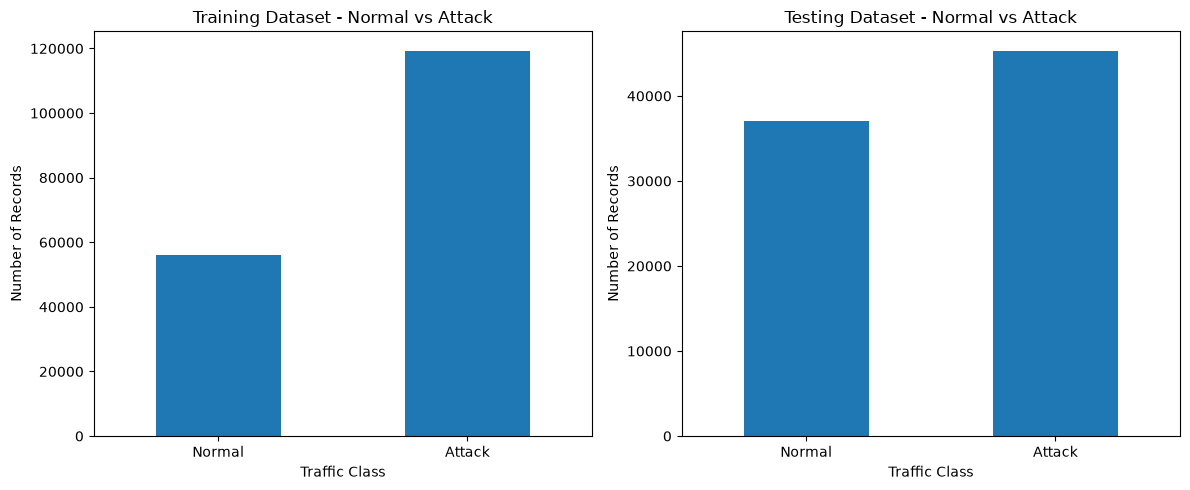

In [14]:
import matplotlib.pyplot as plt

# --------------------------------------------------
# Binary label distribution
# --------------------------------------------------

train_label_counts = train_df["label"].value_counts().sort_index()
test_label_counts = test_df["label"].value_counts().sort_index()

print("TRAINING LABEL DISTRIBUTION")
print(train_label_counts)

print("\nTESTING LABEL DISTRIBUTION")
print(test_label_counts)


# --------------------------------------------------
# Attack-category distribution
# --------------------------------------------------

print("\nTRAINING ATTACK CATEGORY DISTRIBUTION")
print(train_df["attack_cat"].value_counts())

print("\nTESTING ATTACK CATEGORY DISTRIBUTION")
print(test_df["attack_cat"].value_counts())


# --------------------------------------------------
# Plot binary label distribution
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

train_label_counts.rename({
    0: "Normal",
    1: "Attack"
}).plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("Training Dataset - Normal vs Attack")
axes[0].set_xlabel("Traffic Class")
axes[0].set_ylabel("Number of Records")
axes[0].tick_params(axis="x", rotation=0)


test_label_counts.rename({
    0: "Normal",
    1: "Attack"
}).plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("Testing Dataset - Normal vs Attack")
axes[1].set_xlabel("Traffic Class")
axes[1].set_ylabel("Number of Records")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [15]:
# Categorical feature distributions

categorical_features = ["proto", "service", "state"]

for column in categorical_features:
    print("\n" + "=" * 70)
    print(f"{column.upper()} DISTRIBUTION")
    print("=" * 70)

    print(train_df[column].value_counts().head(20))


PROTO DISTRIBUTION
proto
tcp          79946
udp          63283
unas         12084
arp           2859
ospf          2595
sctp          1150
any            300
gre            225
sun-nd         201
swipe          201
mobile         201
pim            201
ipv6           201
rsvp           200
sep            193
ib             101
ddp            100
ipv6-frag      100
cftp           100
wsn            100
Name: count, dtype: int64

SERVICE DISTRIBUTION
service
-           94168
dns         47294
http        18724
smtp         5058
ftp-data     3995
ftp          3428
ssh          1302
pop3         1105
dhcp           94
snmp           80
ssl            56
irc            25
radius         12
Name: count, dtype: int64

STATE DISTRIBUTION
state
INT    82275
FIN    77825
CON    13152
REQ     1991
RST       83
ECO       12
PAR        1
URN        1
no         1
Name: count, dtype: int64


In [16]:
# Compare categorical features between Normal and Attack traffic

for column in ["proto", "service", "state"]:
    print("\n" + "=" * 70)
    print(f"{column.upper()} vs LABEL")
    print("=" * 70)

    distribution = pd.crosstab(
        train_df[column],
        train_df["label"],
        normalize="index"
    ) * 100

    distribution.columns = ["Normal (%)", "Attack (%)"]

    print(distribution.sort_values("Attack (%)", ascending=False).head(20).round(2))


PROTO vs LABEL
             Normal (%)  Attack (%)
proto                              
3pc                 0.0       100.0
a/n                 0.0       100.0
aes-sp3-d           0.0       100.0
any                 0.0       100.0
argus               0.0       100.0
aris                0.0       100.0
ax.25               0.0       100.0
bbn-rcc             0.0       100.0
bna                 0.0       100.0
cbt                 0.0       100.0
br-sat-mon          0.0       100.0
cftp                0.0       100.0
chaos               0.0       100.0
crtp                0.0       100.0
compaq-peer         0.0       100.0
cphb                0.0       100.0
cpnx                0.0       100.0
dcn                 0.0       100.0
crudp               0.0       100.0
ddp                 0.0       100.0

SERVICE vs LABEL
          Normal (%)  Attack (%)
service                         
dhcp            0.00      100.00
ssl             0.00      100.00
irc             0.00      100.00
pop3     

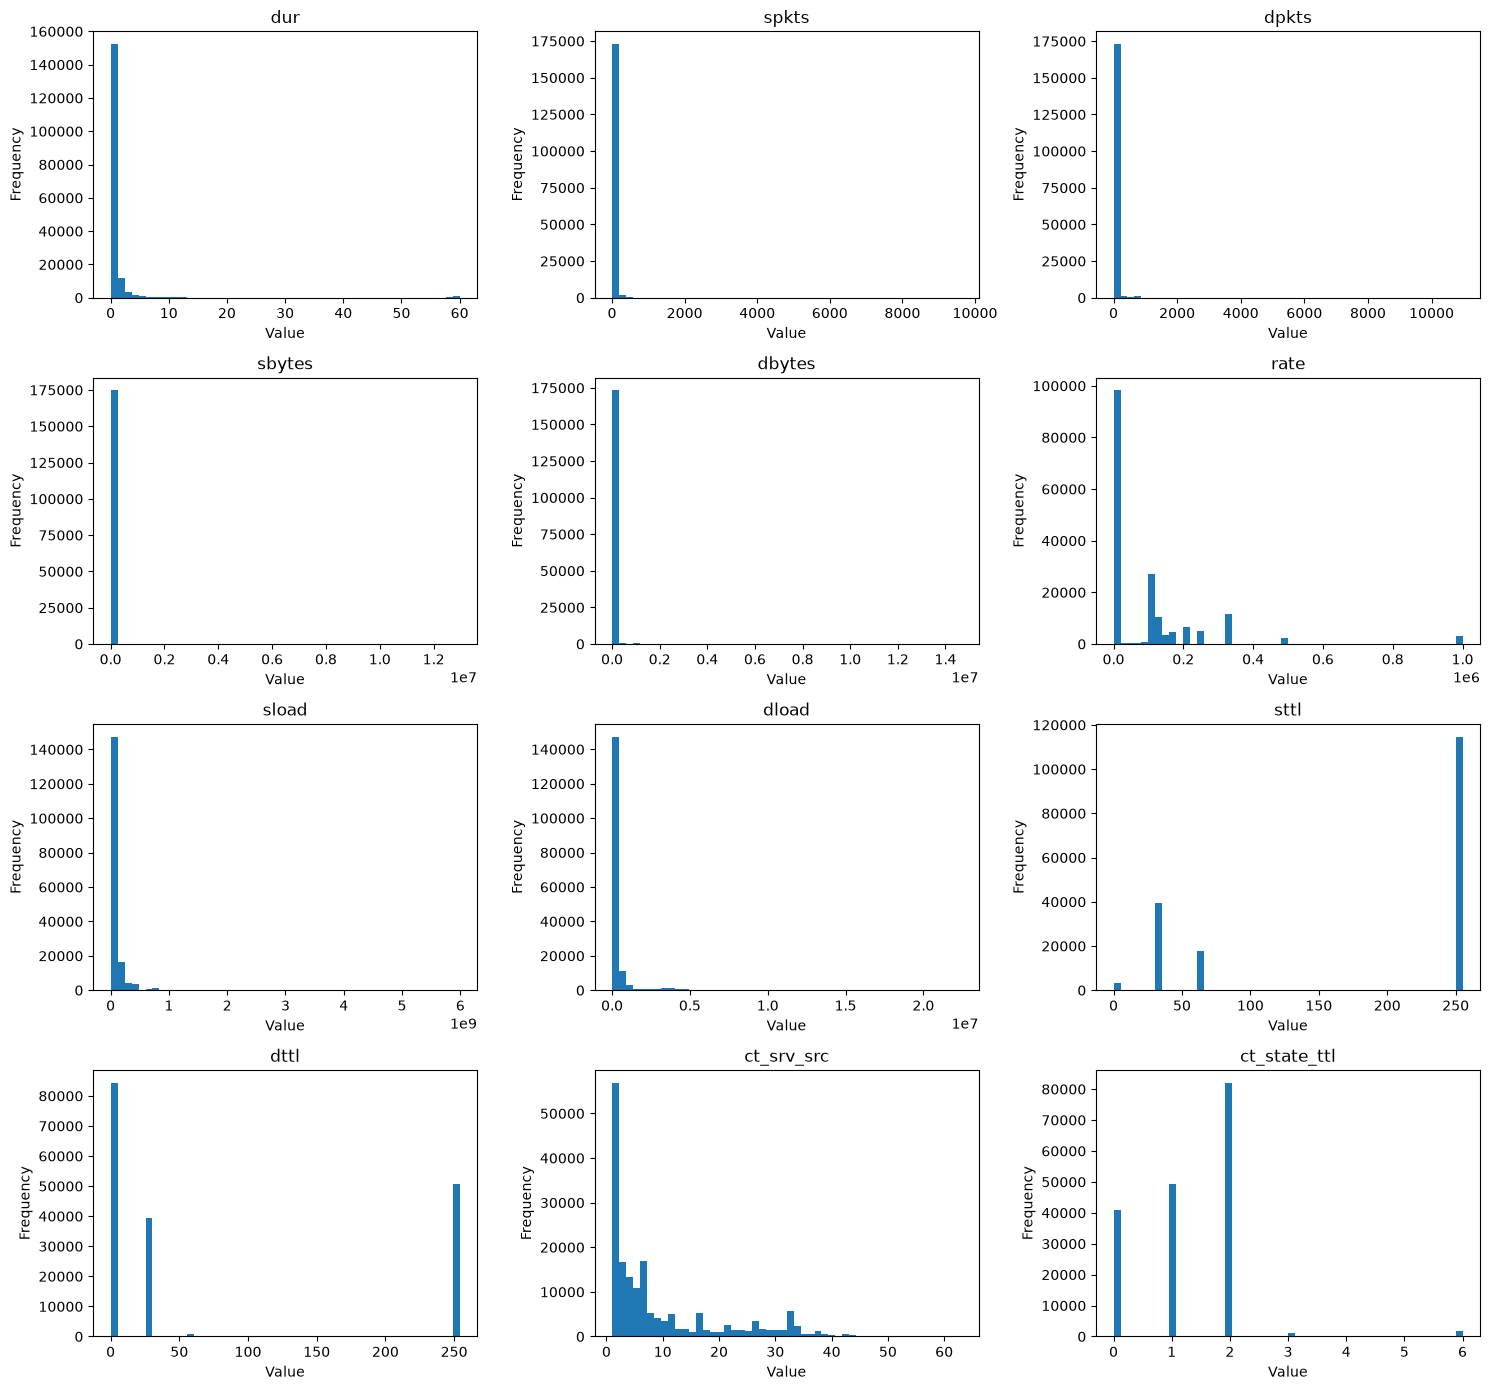

In [17]:
import matplotlib.pyplot as plt

# Representative numerical features for distribution inspection
selected_features = [
    "dur",
    "spkts",
    "dpkts",
    "sbytes",
    "dbytes",
    "rate",
    "sload",
    "dload",
    "sttl",
    "dttl",
    "ct_srv_src",
    "ct_state_ttl"
]

fig, axes = plt.subplots(4, 3, figsize=(15, 14))

for ax, feature in zip(axes.flatten(), selected_features):
    ax.hist(train_df[feature], bins=50)
    ax.set_title(feature)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [18]:
# Quantify skewness and zero concentration

numerical_features = [
    col for col in train_df.select_dtypes(
        include=["int64", "float64"]
    ).columns
    if col not in ["id", "label"]
]

eda_summary = pd.DataFrame(index=numerical_features)

eda_summary["mean"] = train_df[numerical_features].mean()
eda_summary["median"] = train_df[numerical_features].median()
eda_summary["std"] = train_df[numerical_features].std()
eda_summary["skewness"] = train_df[numerical_features].skew()
eda_summary["zero_%"] = (
    (train_df[numerical_features] == 0).mean() * 100
)

# Sort by absolute skewness
eda_summary["abs_skewness"] = eda_summary["skewness"].abs()

print("MOST SKEWED NUMERICAL FEATURES")
print("=" * 80)

display(
    eda_summary
    .sort_values("abs_skewness", ascending=False)
    .drop(columns="abs_skewness")
    .head(20)
)

print("\n\nFEATURES WITH HIGHEST ZERO CONCENTRATION")
print("=" * 80)

display(
    eda_summary
    .sort_values("zero_%", ascending=False)
    .drop(columns="abs_skewness")
    .head(20)
)

MOST SKEWED NUMERICAL FEATURES


,mean,median,std,skewness,zero_%
trans_depth,1.059821e-01,0.000000,7.769108e-01,167.335829,89.825540
response_body_len,2.144292e+03,0.000000,5.420797e+04,76.340075,93.558837
sbytes,8.844844e+03,430.000000,1.747656e+05,45.303443,0.000000
sloss,4.953000e+00,0.000000,6.600506e+01,44.753662,54.435643
dloss,6.948010e+00,0.000000,5.273300e+01,41.380270,55.113750
spkts,2.029866e+01,2.000000,1.368876e+02,40.217703,0.000000
dbytes,1.492892e+04,164.000000,1.436542e+05,39.760864,48.067480
dpkts,1.896959e+01,2.000000,1.102583e+02,36.764114,48.067480
dinpkt,8.821630e+01,0.006000,9.870932e+02,29.679512,48.073753
djit,6.043538e+02,0.000000,4.061043e+03,29.543830,53.463252




FEATURES WITH HIGHEST ZERO CONCENTRATION


,mean,median,std,skewness,zero_%
ct_ftp_cmd,1.494802e-02,0.000000,1.260480e-01,9.943196,98.535996
is_ftp_login,1.494802e-02,0.000000,1.260480e-01,9.943196,98.535996
is_sm_ips_ports,1.575216e-02,0.000000,1.245155e-01,7.778199,98.424784
response_body_len,2.144292e+03,0.000000,5.420797e+04,76.340075,93.558837
trans_depth,1.059821e-01,0.000000,7.769108e-01,167.335829,89.825540
ct_flw_http_mthd,1.330664e-01,0.000000,7.012076e-01,23.451424,89.825540
dloss,6.948010e+00,0.000000,5.273300e+01,41.380270,55.113750
ackdat,2.037519e-02,0.000000,4.050636e-02,5.615605,54.922123
tcprtt,4.139564e-02,0.000000,7.935397e-02,4.038359,54.921553
synack,2.102045e-02,0.000000,4.339978e-02,5.786286,54.921553


In [19]:
# Step 11: Duplicate and train/test overlap check

# Columns representing the actual network traffic information
feature_columns = [
    col for col in train_df.columns
    if col not in ["id", "attack_cat", "label"]
]

print("Number of traffic feature columns:", len(feature_columns))

# --------------------------------------------------
# 1. Duplicate rows within each dataset
# --------------------------------------------------

train_duplicates = train_df.duplicated().sum()
test_duplicates = test_df.duplicated().sum()

print("\nDUPLICATE ROWS")
print("=" * 60)
print("Duplicate rows in training dataset:", train_duplicates)
print("Duplicate rows in testing dataset :", test_duplicates)


# --------------------------------------------------
# 2. Duplicate traffic records within each dataset
#    (excluding ID and targets)
# --------------------------------------------------

train_feature_duplicates = train_df[feature_columns].duplicated().sum()
test_feature_duplicates = test_df[feature_columns].duplicated().sum()

print("\nDUPLICATE TRAFFIC RECORDS")
print("=" * 60)
print("Duplicate traffic records in training:", train_feature_duplicates)
print("Duplicate traffic records in testing :", test_feature_duplicates)


# --------------------------------------------------
# 3. Exact traffic-feature overlap between
#    training and testing
# --------------------------------------------------

train_feature_set = set(
    map(tuple, train_df[feature_columns].to_numpy())
)

test_feature_set = set(
    map(tuple, test_df[feature_columns].to_numpy())
)

overlap_count = len(train_feature_set.intersection(test_feature_set))

print("\nTRAIN/TEST TRAFFIC OVERLAP")
print("=" * 60)
print("Unique traffic records in training:", len(train_feature_set))
print("Unique traffic records in testing :", len(test_feature_set))
print("Exact traffic records appearing in both:", overlap_count)

Number of traffic feature columns: 42

DUPLICATE ROWS
Duplicate rows in training dataset: 0
Duplicate rows in testing dataset : 0

DUPLICATE TRAFFIC RECORDS
Duplicate traffic records in training: 74301
Duplicate traffic records in testing : 28386

TRAIN/TEST TRAFFIC OVERLAP
Unique traffic records in training: 101040
Unique traffic records in testing : 53946
Exact traffic records appearing in both: 1302


In [20]:
# Step 12: Check label consistency among duplicate traffic records

# Group identical traffic-feature records
duplicate_groups = (
    train_df
    .groupby(feature_columns)["label"]
    .agg(["count", "nunique"])
)

# Duplicate feature groups
duplicate_groups = duplicate_groups[duplicate_groups["count"] > 1]

print("Duplicate traffic-feature groups:", len(duplicate_groups))

# Groups containing more than one label
conflicting_groups = duplicate_groups[
    duplicate_groups["nunique"] > 1
]

print(
    "Duplicate feature groups with conflicting binary labels:",
    len(conflicting_groups)
)

# Show examples if any exist
if len(conflicting_groups) > 0:
    print("\nExamples of conflicting groups:")
    display(conflicting_groups.head(10))
else:
    print("\nNo conflicting binary labels found among duplicate traffic records.")

Duplicate traffic-feature groups: 9748
Duplicate feature groups with conflicting binary labels: 229

Examples of conflicting groups:


count  \
dur      proto service state spkts dpkts sbytes dbytes rate        sttl dttl sload       dload sloss dloss sinpkt dinpkt sjit djit swin stcpb dtcpb dwin tcprtt synack ackdat smean dmean trans_depth response_body_len ct_srv_src ct_state_ttl ct_dst_ltm ct_src_dport_ltm ct_dst_sport_ltm ct_dst_src_ltm is_ftp_login ct_ftp_cmd ct_flw_http_mthd ct_src_ltm ct_srv_dst is_sm_ips_ports          
0.000001 udp   -       INT   2     0     104    0      1000000.003 254  0    416000000.0 0.0   0     0     0.001  0.0    0.0  0.0  0    0     0     0    0.0    0.0    0.0    52    0     0           0                 1          2            1          1                1                1              0            0          0                1          1          0                    2   
                                                                                                                                                                                                                                                                                                                                                     2          1          0                    2   
                                                                                                                                                                                                                        2          2            1          1                1                1              0            0          0                1          1          0                    3   
                                                                                                                                                                                                                                                                                             2              0            0          0                1          2          0                    7   
                                                                                                                                                                                                                                                                                                                                                                3          0                    2   
                                                                                                                                                                                                                        3          2            1          1                1                2              0            0          0                1          2          0                    3   
                                                                                                                                                                                                                                                                                                                                                     2          2          0                    3   
                                                                                                                                                                                                                                                                                             3              0            0          0                1          3          0                    5   
                                                                                                                                                                                                                                                2          2                1                3              0            0          0                2          3          0                    2   
                                                                                                     

In [21]:
# Step 12A: Quantify conflicting traffic-feature groups

# Find traffic-feature patterns that have both Normal and Attack labels
conflicting_features = (
    train_df
    .groupby(feature_columns)["label"]
    .agg(["count", "nunique", "sum"])
)

conflicting_features = conflicting_features[
    (conflicting_features["count"] > 1) &
    (conflicting_features["nunique"] > 1)
]

print("Number of conflicting feature groups:", len(conflicting_features))

print("\nTotal training records belonging to conflicting groups:",
      conflicting_features["count"].sum())

print("\nLabel distribution inside conflicting groups:")
print(
    train_df[
        train_df.set_index(feature_columns).index.isin(
            conflicting_features.index
        )
    ]["label"].value_counts()
)

# --------------------------------------------------
# Show a few conflicting groups with their labels
# --------------------------------------------------

print("\nExample conflicting groups:")
display(conflicting_features.head(10))

Number of conflicting feature groups: 229

Total training records belonging to conflicting groups: 940

Label distribution inside conflicting groups:
label
1    544
0    396
Name: count, dtype: int64

Example conflicting groups:


count  \
dur      proto service state spkts dpkts sbytes dbytes rate        sttl dttl sload       dload sloss dloss sinpkt dinpkt sjit djit swin stcpb dtcpb dwin tcprtt synack ackdat smean dmean trans_depth response_body_len ct_srv_src ct_state_ttl ct_dst_ltm ct_src_dport_ltm ct_dst_sport_ltm ct_dst_src_ltm is_ftp_login ct_ftp_cmd ct_flw_http_mthd ct_src_ltm ct_srv_dst is_sm_ips_ports          
0.000001 udp   -       INT   2     0     104    0      1000000.003 254  0    416000000.0 0.0   0     0     0.001  0.0    0.0  0.0  0    0     0     0    0.0    0.0    0.0    52    0     0           0                 1          2            1          1                1                1              0            0          0                1          1          0                    2   
                                                                                                                                                                                                                                                                                                                                                     2          1          0                    2   
                                                                                                                                                                                                                        2          2            1          1                1                1              0            0          0                1          1          0                    3   
                                                                                                                                                                                                                                                                                             2              0            0          0                1          2          0                    7   
                                                                                                                                                                                                                                                                                                                                                                3          0                    2   
                                                                                                                                                                                                                        3          2            1          1                1                2              0            0          0                1          2          0                    3   
                                                                                                                                                                                                                                                                                                                                                     2          2          0                    3   
                                                                                                                                                                                                                                                                                             3              0            0          0                1          3          0                    5   
                                                                                                                                                                                                                                                2          2                1                3              0            0          0                2          3          0                    2   
                                                                                                     

In [22]:
# Step 12B: Examine attack categories in conflicting feature groups

# Get the feature patterns that have conflicting binary labels
conflicting_index = conflicting_features.index

# Select all training records belonging to those patterns
conflicting_records = train_df[
    train_df.set_index(feature_columns).index.isin(conflicting_index)
].copy()

print("Attack-category distribution within conflicting records:")
print(
    conflicting_records["attack_cat"]
    .value_counts()
)

print("\n\nCross-tabulation of attack category and binary label:")
print(
    pd.crosstab(
        conflicting_records["attack_cat"],
        conflicting_records["label"]
    )
)

Attack-category distribution within conflicting records:
attack_cat
Fuzzers      543
Normal       396
Shellcode      1
Name: count, dtype: int64


Cross-tabulation of attack category and binary label:
label         0    1
attack_cat          
Fuzzers       0  543
Normal      396    0
Shellcode     0    1


In [23]:
# Step 13: Verify consistency between label and attack category

print("TRAINING DATA")
print("=" * 60)

train_crosscheck = pd.crosstab(
    train_df["attack_cat"],
    train_df["label"]
)

print(train_crosscheck)


print("\n\nTESTING DATA")
print("=" * 60)

test_crosscheck = pd.crosstab(
    test_df["attack_cat"],
    test_df["label"]
)

print(test_crosscheck)


# Check whether any Normal category has label 1
train_normal_attack = (
    (train_df["attack_cat"] == "Normal") &
    (train_df["label"] != 0)
).sum()

test_normal_attack = (
    (test_df["attack_cat"] == "Normal") &
    (test_df["label"] != 0)
).sum()


# Check whether any non-Normal category has label 0
train_attack_normal = (
    (train_df["attack_cat"] != "Normal") &
    (train_df["label"] != 1)
).sum()

test_attack_normal = (
    (test_df["attack_cat"] != "Normal") &
    (test_df["label"] != 1)
).sum()


print("\n\nCONSISTENCY CHECK")
print("=" * 60)

print("Training: Normal category with label != 0:", train_normal_attack)
print("Training: Attack category with label != 1:", train_attack_normal)

print("Testing : Normal category with label != 0:", test_normal_attack)
print("Testing : Attack category with label != 1:", test_attack_normal)

TRAINING DATA
label               0      1
attack_cat                  
Analysis            0   2000
Backdoor            0   1746
DoS                 0  12264
Exploits            0  33393
Fuzzers             0  18184
Generic             0  40000
Normal          56000      0
Reconnaissance      0  10491
Shellcode           0   1133
Worms               0    130


TESTING DATA
label               0      1
attack_cat                  
Analysis            0    677
Backdoor            0    583
DoS                 0   4089
Exploits            0  11132
Fuzzers             0   6062
Generic             0  18871
Normal          37000      0
Reconnaissance      0   3496
Shellcode           0    378
Worms               0     44


CONSISTENCY CHECK
Training: Normal category with label != 0: 0
Training: Attack category with label != 1: 0
Testing : Normal category with label != 0: 0
Testing : Attack category with label != 1: 0


In [24]:
# Step 14: Create feature and target variables

# Remove identifier and target columns from model inputs
feature_columns = [
    col for col in train_df.columns
    if col not in ["id", "attack_cat", "label"]
]

# Input features
X_train = train_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()

# Binary target
y_train_binary = train_df["label"].copy()
y_test_binary = test_df["label"].copy()

# Multiclass target
y_train_multiclass = train_df["attack_cat"].copy()
y_test_multiclass = test_df["attack_cat"].copy()

print("Feature matrix:")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("\nBinary targets:")
print("y_train_binary:", y_train_binary.shape)
print("y_test_binary :", y_test_binary.shape)

print("\nMulticlass targets:")
print("y_train_multiclass:", y_train_multiclass.shape)
print("y_test_multiclass :", y_test_multiclass.shape)

print("\nFeatures used by models:", len(feature_columns))
print(feature_columns)

Feature matrix:
X_train: (175341, 42)
X_test : (82332, 42)

Binary targets:
y_train_binary: (175341,)
y_test_binary : (82332,)

Multiclass targets:
y_train_multiclass: (175341,)
y_test_multiclass : (82332,)

Features used by models: 42
['dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']


In [25]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [26]:
from sklearn.model_selection import train_test_split

print("Scikit-learn installed successfully!")

Scikit-learn installed successfully!


In [27]:
from sklearn.model_selection import train_test_split

# Split the original training data into training and validation sets
X_train_split, X_val, y_train_split, y_val = train_test_split(
    X_train,
    y_train_binary,
    test_size=0.20,
    random_state=42,
    stratify=y_train_binary
)

print("Training set:")
print("X_train_split:", X_train_split.shape)
print("y_train_split:", y_train_split.shape)

print("\nValidation set:")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nFinal test set (untouched):")
print("X_test:", X_test.shape)
print("y_test_binary:", y_test_binary.shape)

# Check class proportions
print("\nBinary class distribution:")
print("Training split:")
print(y_train_split.value_counts(normalize=True).sort_index())

print("\nValidation split:")
print(y_val.value_counts(normalize=True).sort_index())

Training set:
X_train_split: (140272, 42)
y_train_split: (140272,)

Validation set:
X_val: (35069, 42)
y_val: (35069,)

Final test set (untouched):
X_test: (82332, 42)
y_test_binary: (82332,)

Binary class distribution:
Training split:
label
0    0.319379
1    0.680621
Name: proportion, dtype: float64

Validation split:
label
0    0.31937
1    0.68063
Name: proportion, dtype: float64


In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Define feature groups
categorical_features = ["proto", "service", "state"]

numerical_features = [
    col for col in X_train_split.columns
    if col not in categorical_features
]

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

print("\nPreprocessor created successfully.")

Numerical features: 39
Categorical features: 3

Preprocessor created successfully.


In [29]:
# Fit preprocessing ONLY on the training split
X_train_processed = preprocessor.fit_transform(X_train_split)

# Transform validation data using the already-fitted preprocessor
X_val_processed = preprocessor.transform(X_val)

print("Original training shape:", X_train_split.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal validation shape:", X_val.shape)
print("Processed validation shape:", X_val_processed.shape)

print("\nProcessed data type:", type(X_train_processed))

Original training shape: (140272, 42)
Processed training shape: (140272, 192)

Original validation shape: (35069, 42)
Processed validation shape: (35069, 192)

Processed data type: <class 'scipy.sparse._csr.csr_matrix'>


In [30]:
# Get the feature names after preprocessing

processed_feature_names = preprocessor.get_feature_names_out()

print("Number of processed features:", len(processed_feature_names))

print("\nFirst 30 processed features:")
for i, name in enumerate(processed_feature_names[:30], start=1):
    print(f"{i:2}. {name}")

print("\nLast 20 processed features:")
for i, name in enumerate(
    processed_feature_names[-20:],
    start=len(processed_feature_names) - 19
):
    print(f"{i:3}. {name}")

Number of processed features: 192

First 30 processed features:
 1. num__dur
 2. num__spkts
 3. num__dpkts
 4. num__sbytes
 5. num__dbytes
 6. num__rate
 7. num__sttl
 8. num__dttl
 9. num__sload
10. num__dload
11. num__sloss
12. num__dloss
13. num__sinpkt
14. num__dinpkt
15. num__sjit
16. num__djit
17. num__swin
18. num__stcpb
19. num__dtcpb
20. num__dwin
21. num__tcprtt
22. num__synack
23. num__ackdat
24. num__smean
25. num__dmean
26. num__trans_depth
27. num__response_body_len
28. num__ct_srv_src
29. num__ct_state_ttl
30. num__ct_dst_ltm

Last 20 processed features:
173. cat__service_-
174. cat__service_dhcp
175. cat__service_dns
176. cat__service_ftp
177. cat__service_ftp-data
178. cat__service_http
179. cat__service_irc
180. cat__service_pop3
181. cat__service_radius
182. cat__service_smtp
183. cat__service_snmp
184. cat__service_ssh
185. cat__service_ssl
186. cat__state_CON
187. cat__state_ECO
188. cat__state_FIN
189. cat__state_INT
190. cat__state_PAR
191. cat__state_REQ
192. ca

In [31]:
from sklearn.ensemble import RandomForestClassifier
import time

# Create the baseline Random Forest
baseline_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest baseline...")
start_time = time.time()

baseline_rf.fit(
    X_train_processed,
    y_train_split
)

training_time = time.time() - start_time

print("\nTraining completed.")
print(f"Training time: {training_time:.2f} seconds")
print("Number of trees:", baseline_rf.n_estimators)

Training Random Forest baseline...

Training completed.
Training time: 44.52 seconds
Number of trees: 100


In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Make predictions on validation data
y_val_pred = baseline_rf.predict(X_val_processed)

# Calculate metrics
accuracy = accuracy_score(y_val, y_val_pred)
precision = precision_score(y_val, y_val_pred, zero_division=0)
recall = recall_score(y_val, y_val_pred, zero_division=0)
f1 = f1_score(y_val, y_val_pred, zero_division=0)

# Confusion matrix
cm = confusion_matrix(y_val, y_val_pred)

tn, fp, fn, tp = cm.ravel()

# False-positive rate
false_positive_rate = fp / (fp + tn)

print("RANDOM FOREST BASELINE — VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy          : {accuracy:.4f}")
print(f"Precision         : {precision:.4f}")
print(f"Recall            : {recall:.4f}")
print(f"F1-score          : {f1:.4f}")
print(f"False-positive rate: {false_positive_rate:.4f}")

print("\nConfusion Matrix")
print("=" * 60)
print(cm)

print("\nClassification Report")
print("=" * 60)

print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=["Normal", "Attack"],
        digits=4,
        zero_division=0
    )
)

RANDOM FOREST BASELINE — VALIDATION RESULTS
Accuracy          : 0.9591
Precision         : 0.9632
Recall            : 0.9772
F1-score          : 0.9702
False-positive rate: 0.0795

Confusion Matrix
[[10310   890]
 [  545 23324]]

Classification Report
              precision    recall  f1-score   support

      Normal     0.9498    0.9205    0.9349     11200
      Attack     0.9632    0.9772    0.9702     23869

    accuracy                         0.9591     35069
   macro avg     0.9565    0.9489    0.9525     35069
weighted avg     0.9589    0.9591    0.9589     35069



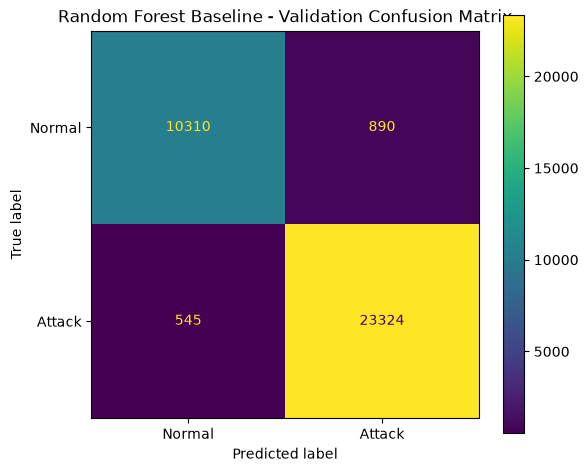

In [33]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Attack"]
)

fig, ax = plt.subplots(figsize=(6, 5))

disp.plot(
    ax=ax,
    values_format="d"
)

ax.set_title("Random Forest Baseline - Validation Confusion Matrix")

plt.tight_layout()
plt.show()

In [34]:
# Step 22: Create multiclass targets matching the existing split

# Match attack categories to the exact rows used in the
# binary training/validation split
y_train_multi_split = y_train_multiclass.loc[X_train_split.index]
y_val_multi = y_train_multiclass.loc[X_val.index]

print("Multiclass training target:")
print("Shape:", y_train_multi_split.shape)

print("\nMulticlass validation target:")
print("Shape:", y_val_multi.shape)

print("\nTraining attack-category distribution:")
print(y_train_multi_split.value_counts())

print("\nValidation attack-category distribution:")
print(y_val_multi.value_counts())

Multiclass training target:
Shape: (140272,)

Multiclass validation target:
Shape: (35069,)

Training attack-category distribution:
attack_cat
Normal            44800
Generic           31995
Exploits          26810
Fuzzers           14510
DoS                9781
Reconnaissance     8356
Analysis           1578
Backdoor           1432
Shellcode           908
Worms               102
Name: count, dtype: int64

Validation attack-category distribution:
attack_cat
Normal            11200
Generic            8005
Exploits           6583
Fuzzers            3674
DoS                2483
Reconnaissance     2135
Analysis            422
Backdoor            314
Shellcode           225
Worms                28
Name: count, dtype: int64


In [35]:
from sklearn.ensemble import RandomForestClassifier
import time

# Multiclass Random Forest baseline
multiclass_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

print("Training multiclass Random Forest...")
start_time = time.time()

multiclass_rf.fit(
    X_train_processed,
    y_train_multi_split
)

training_time = time.time() - start_time

print("\nTraining completed.")
print(f"Training time: {training_time:.2f} seconds")
print("Number of trees:", multiclass_rf.n_estimators)
print("Number of classes:", len(multiclass_rf.classes_))
print("\nClasses:")
print(multiclass_rf.classes_)

Training multiclass Random Forest...

Training completed.
Training time: 97.75 seconds
Number of trees: 100
Number of classes: 10

Classes:
['Analysis' 'Backdoor' 'DoS' 'Exploits' 'Fuzzers' 'Generic' 'Normal'
 'Reconnaissance' 'Shellcode' 'Worms']


In [36]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predict validation data
y_val_multi_pred = multiclass_rf.predict(X_val_processed)

# Overall metrics
multi_accuracy = accuracy_score(
    y_val_multi,
    y_val_multi_pred
)

multi_precision_macro = precision_score(
    y_val_multi,
    y_val_multi_pred,
    average="macro",
    zero_division=0
)

multi_recall_macro = recall_score(
    y_val_multi,
    y_val_multi_pred,
    average="macro",
    zero_division=0
)

multi_f1_macro = f1_score(
    y_val_multi,
    y_val_multi_pred,
    average="macro",
    zero_division=0
)

multi_precision_weighted = precision_score(
    y_val_multi,
    y_val_multi_pred,
    average="weighted",
    zero_division=0
)

multi_recall_weighted = recall_score(
    y_val_multi,
    y_val_multi_pred,
    average="weighted",
    zero_division=0
)

multi_f1_weighted = f1_score(
    y_val_multi,
    y_val_multi_pred,
    average="weighted",
    zero_division=0
)

print("MULTICLASS RANDOM FOREST — VALIDATION RESULTS")
print("=" * 70)

print(f"Accuracy              : {multi_accuracy:.4f}")
print(f"Macro Precision       : {multi_precision_macro:.4f}")
print(f"Macro Recall          : {multi_recall_macro:.4f}")
print(f"Macro F1-score        : {multi_f1_macro:.4f}")
print(f"Weighted Precision    : {multi_precision_weighted:.4f}")
print(f"Weighted Recall       : {multi_recall_weighted:.4f}")
print(f"Weighted F1-score     : {multi_f1_weighted:.4f}")

print("\nPER-CLASS CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_val_multi,
        y_val_multi_pred,
        digits=4,
        zero_division=0
    )
)

MULTICLASS RANDOM FOREST — VALIDATION RESULTS
Accuracy              : 0.8249
Macro Precision       : 0.7078
Macro Recall          : 0.5553
Macro F1-score        : 0.5827
Weighted Precision    : 0.8235
Weighted Recall       : 0.8249
Weighted F1-score     : 0.8150

PER-CLASS CLASSIFICATION REPORT
                precision    recall  f1-score   support

      Analysis     0.6875    0.1303    0.2191       422
      Backdoor     0.6719    0.1369    0.2275       314
           DoS     0.3093    0.1845    0.2311      2483
      Exploits     0.6264    0.8580    0.7241      6583
       Fuzzers     0.7696    0.7463    0.7578      3674
       Generic     0.9985    0.9803    0.9893      8005
        Normal     0.9414    0.9307    0.9360     11200
Reconnaissance     0.9195    0.7274    0.8122      2135
     Shellcode     0.6538    0.6800    0.6667       225
         Worms     0.5000    0.1786    0.2632        28

      accuracy                         0.8249     35069
     macro avg     0.7078    0

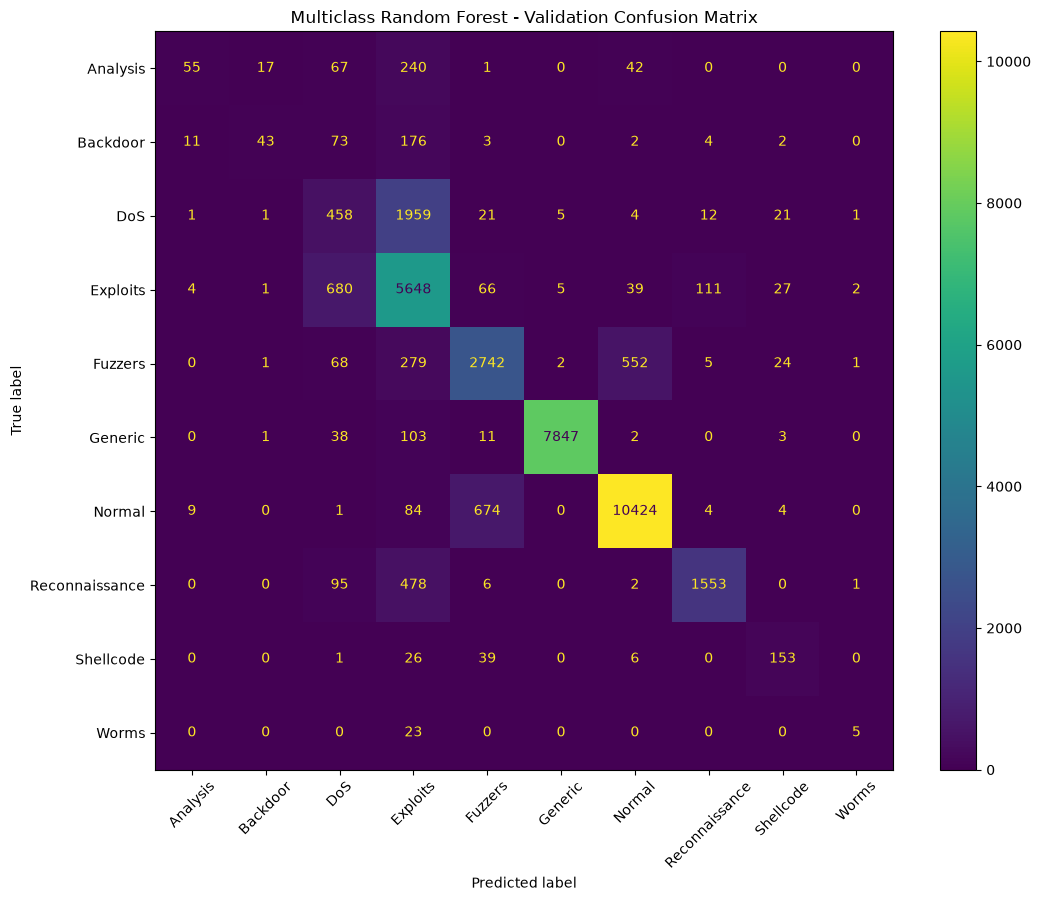

In [37]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Create multiclass confusion matrix
multi_cm = confusion_matrix(
    y_val_multi,
    y_val_multi_pred,
    labels=multiclass_rf.classes_
)

# Plot
fig, ax = plt.subplots(figsize=(11, 9))

disp = ConfusionMatrixDisplay(
    confusion_matrix=multi_cm,
    display_labels=multiclass_rf.classes_
)

disp.plot(
    ax=ax,
    values_format="d",
    xticks_rotation=45
)

ax.set_title(
    "Multiclass Random Forest - Validation Confusion Matrix"
)

plt.tight_layout()
plt.show()

In [38]:
# Step 26: Prepare normal-only data for anomaly detection

# Select only normal traffic from the training split
normal_train_mask = y_train_split == 0

X_anomaly_train = X_train_split.loc[normal_train_mask].copy()

print("Normal records available for anomaly training:")
print("X_anomaly_train:", X_anomaly_train.shape)

print("\nNormal records used:", normal_train_mask.sum())

print("\nValidation set:")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nValidation label distribution:")
print(y_val.value_counts())

Normal records available for anomaly training:
X_anomaly_train: (44800, 42)

Normal records used: 44800

Validation set:
X_val: (35069, 42)
y_val: (35069,)

Validation label distribution:
label
1    23869
0    11200
Name: count, dtype: int64


In [39]:
from sklearn.model_selection import train_test_split

# Split normal-only data into:
# 80% for anomaly detector training
# 20% for threshold calibration

X_anomaly_fit, X_anomaly_calibration = train_test_split(
    X_anomaly_train,
    test_size=0.20,
    random_state=42
)

print("Anomaly detector training data:")
print("X_anomaly_fit:", X_anomaly_fit.shape)

print("\nThreshold calibration data:")
print("X_anomaly_calibration:", X_anomaly_calibration.shape)

print("\nTotal normal records:")
print(
    len(X_anomaly_fit) +
    len(X_anomaly_calibration)
)

Anomaly detector training data:
X_anomaly_fit: (35840, 42)

Threshold calibration data:
X_anomaly_calibration: (8960, 42)

Total normal records:
44800


In [40]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Separate preprocessing for anomaly detection
anomaly_categorical_features = ["proto", "service", "state"]

anomaly_numerical_features = [
    col for col in X_anomaly_fit.columns
    if col not in anomaly_categorical_features
]

anomaly_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            anomaly_numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            anomaly_categorical_features
        )
    ]
)

# Fit ONLY on normal anomaly-training data
X_anomaly_fit_processed = anomaly_preprocessor.fit_transform(
    X_anomaly_fit
)

# Transform normal calibration data
X_anomaly_calibration_processed = anomaly_preprocessor.transform(
    X_anomaly_calibration
)

# Transform the mixed validation set
X_val_anomaly_processed = anomaly_preprocessor.transform(
    X_val
)

print("Anomaly preprocessing completed.")

print("\nTraining:")
print(X_anomaly_fit_processed.shape)

print("\nCalibration:")
print(X_anomaly_calibration_processed.shape)

print("\nValidation:")
print(X_val_anomaly_processed.shape)

Anomaly preprocessing completed.

Training:
(35840, 63)

Calibration:
(8960, 63)

Validation:
(35069, 63)


In [41]:
from sklearn.ensemble import IsolationForest
import time

# Create the Isolation Forest anomaly detector
isolation_forest = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

print("Training Isolation Forest...")
start_time = time.time()

isolation_forest.fit(
    X_anomaly_fit_processed
)

training_time = time.time() - start_time

print("\nTraining completed.")
print(f"Training time: {training_time:.2f} seconds")
print("Number of trees:", isolation_forest.n_estimators)

Training Isolation Forest...

Training completed.
Training time: 0.95 seconds
Number of trees: 200


In [42]:
# Step 30: Calculate anomaly scores on normal calibration data

calibration_scores = -isolation_forest.score_samples(
    X_anomaly_calibration_processed
)

print("Anomaly scores calculated.")
print("Number of calibration scores:", len(calibration_scores))

print("\nCalibration anomaly-score statistics:")
print("=" * 60)

print(f"Minimum : {calibration_scores.min():.6f}")
print(f"Maximum : {calibration_scores.max():.6f}")
print(f"Mean    : {calibration_scores.mean():.6f}")
print(f"Median  : {__import__('numpy').median(calibration_scores):.6f}")
print(f"Std     : {calibration_scores.std():.6f}")

print("\nSelected percentiles:")
for percentile in [90, 95, 97, 98, 99, 99.5]:
    value = __import__('numpy').percentile(
        calibration_scores,
        percentile
    )
    print(f"{percentile:5.1f}% : {value:.6f}")

Anomaly scores calculated.
Number of calibration scores: 8960

Calibration anomaly-score statistics:
Minimum : 0.336453
Maximum : 0.634110
Mean    : 0.408278
Median  : 0.394424
Std     : 0.050075

Selected percentiles:
 90.0% : 0.478277
 95.0% : 0.512757
 97.0% : 0.538114
 98.0% : 0.551638
 99.0% : 0.576605
 99.5% : 0.588378


In [43]:
import numpy as np

# Primary anomaly threshold
anomaly_threshold = np.percentile(
    calibration_scores,
    99
)

print("ANOMALY DETECTION THRESHOLD")
print("=" * 60)

print(f"Threshold: {anomaly_threshold:.6f}")

print("\nThreshold rule:")
print("99th percentile of normal calibration anomaly scores")

print("\nExpected calibration behavior:")
print("Approximately 1% of normal calibration records")
print("will be flagged as anomalous.")

ANOMALY DETECTION THRESHOLD
Threshold: 0.576605

Threshold rule:
99th percentile of normal calibration anomaly scores

Expected calibration behavior:
Approximately 1% of normal calibration records
will be flagged as anomalous.


In [44]:
# Step 32: Evaluate Isolation Forest on mixed validation data

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Calculate anomaly scores for validation data
val_anomaly_scores = -isolation_forest.score_samples(
    X_val_anomaly_processed
)

# Apply the threshold selected from normal calibration data
y_val_anomaly_pred = (
    val_anomaly_scores >= anomaly_threshold
).astype(int)

# Actual labels
y_val_anomaly_true = y_val.to_numpy()

# Calculate metrics
anomaly_accuracy = accuracy_score(
    y_val_anomaly_true,
    y_val_anomaly_pred
)

anomaly_precision = precision_score(
    y_val_anomaly_true,
    y_val_anomaly_pred,
    zero_division=0
)

anomaly_recall = recall_score(
    y_val_anomaly_true,
    y_val_anomaly_pred,
    zero_division=0
)

anomaly_f1 = f1_score(
    y_val_anomaly_true,
    y_val_anomaly_pred,
    zero_division=0
)

# Confusion matrix
anomaly_cm = confusion_matrix(
    y_val_anomaly_true,
    y_val_anomaly_pred
)

tn, fp, fn, tp = anomaly_cm.ravel()

# False-positive rate
anomaly_fpr = fp / (fp + tn)

print("ISOLATION FOREST — VALIDATION RESULTS")
print("=" * 65)

print(f"Threshold          : {anomaly_threshold:.6f}")
print(f"Accuracy           : {anomaly_accuracy:.4f}")
print(f"Precision          : {anomaly_precision:.4f}")
print(f"Recall             : {anomaly_recall:.4f}")
print(f"F1-score           : {anomaly_f1:.4f}")
print(f"False-positive rate: {anomaly_fpr:.4f}")

print("\nConfusion Matrix")
print("=" * 65)
print(anomaly_cm)

print("\nClassification Report")
print("=" * 65)

print(
    classification_report(
        y_val_anomaly_true,
        y_val_anomaly_pred,
        target_names=["Normal", "Anomaly"],
        digits=4,
        zero_division=0
    )
)

ISOLATION FOREST — VALIDATION RESULTS
Threshold          : 0.576605
Accuracy           : 0.3942
Precision          : 0.9623
Recall             : 0.1144
F1-score           : 0.2045
False-positive rate: 0.0096

Confusion Matrix
[[11093   107]
 [21138  2731]]

Classification Report
              precision    recall  f1-score   support

      Normal     0.3442    0.9904    0.5108     11200
     Anomaly     0.9623    0.1144    0.2045     23869

    accuracy                         0.3942     35069
   macro avg     0.6532    0.5524    0.3577     35069
weighted avg     0.7649    0.3942    0.3023     35069



Validation anomaly-score statistics

Normal traffic:
Count  : 11200
Mean   : 0.407769
Median : 0.394659
95th % : 0.507018

Attack traffic:
Count  : 23869
Mean   : 0.487200
Median : 0.467393
5th %  : 0.388170

Fixed anomaly threshold:
0.576605


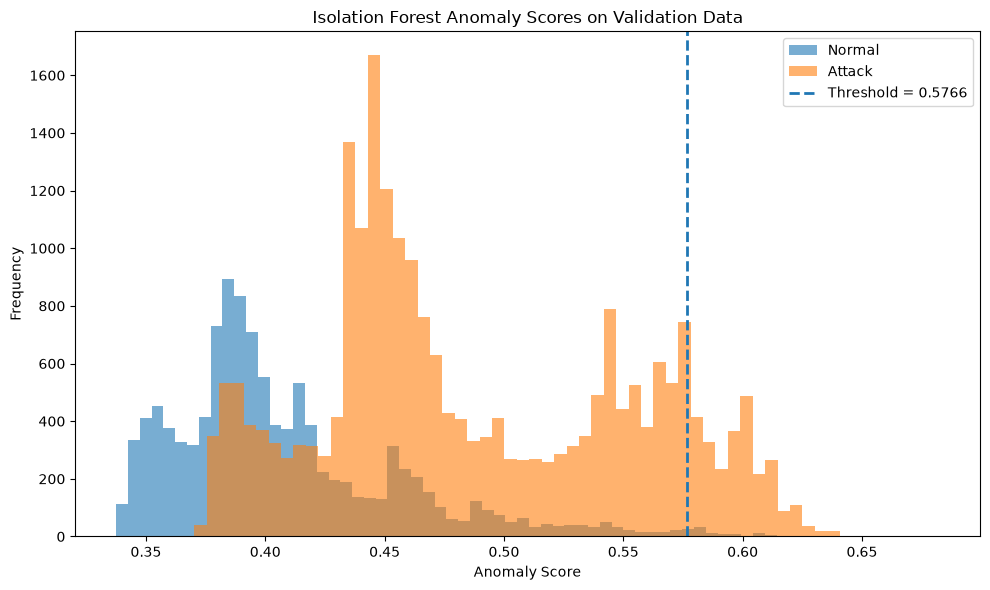

In [45]:
import matplotlib.pyplot as plt

# Separate validation anomaly scores by true class
normal_scores = val_anomaly_scores[y_val_anomaly_true == 0]
attack_scores = val_anomaly_scores[y_val_anomaly_true == 1]

print("Validation anomaly-score statistics")
print("=" * 65)

print("\nNormal traffic:")
print(f"Count  : {len(normal_scores)}")
print(f"Mean   : {normal_scores.mean():.6f}")
print(f"Median : {__import__('numpy').median(normal_scores):.6f}")
print(f"95th % : {__import__('numpy').percentile(normal_scores, 95):.6f}")

print("\nAttack traffic:")
print(f"Count  : {len(attack_scores)}")
print(f"Mean   : {attack_scores.mean():.6f}")
print(f"Median : {__import__('numpy').median(attack_scores):.6f}")
print(f"5th %  : {__import__('numpy').percentile(attack_scores, 5):.6f}")

print("\nFixed anomaly threshold:")
print(f"{anomaly_threshold:.6f}")

# Plot distributions
plt.figure(figsize=(10, 6))

plt.hist(
    normal_scores,
    bins=60,
    alpha=0.6,
    label="Normal"
)

plt.hist(
    attack_scores,
    bins=60,
    alpha=0.6,
    label="Attack"
)

plt.axvline(
    anomaly_threshold,
    linestyle="--",
    linewidth=2,
    label=f"Threshold = {anomaly_threshold:.4f}"
)

plt.xlabel("Anomaly Score")
plt.ylabel("Frequency")
plt.title("Isolation Forest Anomaly Scores on Validation Data")
plt.legend()
plt.tight_layout()
plt.show()

In [46]:
# Step 34: Anomaly detection performance by attack category

import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

# Create a temporary analysis dataframe
anomaly_category_results = pd.DataFrame({
    "attack_cat": y_val_multi.values,
    "anomaly_prediction": y_val_anomaly_pred,
    "true_label": y_val_anomaly_true
})

# Calculate metrics separately for each attack category
category_rows = []

for category in multiclass_rf.classes_:

    # Select records belonging to this category
    mask = anomaly_category_results["attack_cat"] == category

    true_binary = anomaly_category_results.loc[
        mask, "true_label"
    ]

    predicted_binary = anomaly_category_results.loc[
        mask, "anomaly_prediction"
    ]

    # Normal category is treated separately
    if category == "Normal":
        precision = precision_score(
            true_binary,
            predicted_binary,
            zero_division=0
        )
        recall = recall_score(
            true_binary,
            predicted_binary,
            zero_division=0
        )
        f1 = f1_score(
            true_binary,
            predicted_binary,
            zero_division=0
        )
    else:
        # Every record in an attack category is actually an attack
        true_attack = [1] * len(true_binary)

        precision = precision_score(
            true_attack,
            predicted_binary,
            zero_division=0
        )

        recall = recall_score(
            true_attack,
            predicted_binary,
            zero_division=0
        )

        f1 = f1_score(
            true_attack,
            predicted_binary,
            zero_division=0
        )

    category_rows.append({
        "Attack Category": category,
        "Records": mask.sum(),
        "Detected as Anomaly": int(predicted_binary.sum()),
        "Detection Rate": recall,
        "F1-score": f1
    })

anomaly_category_results_table = pd.DataFrame(category_rows)

print("ANOMALY DETECTION BY ATTACK CATEGORY")
print("=" * 80)

print(
    anomaly_category_results_table.to_string(
        index=False,
        formatters={
            "Detection Rate": "{:.4f}".format,
            "F1-score": "{:.4f}".format
        }
    )
)

ANOMALY DETECTION BY ATTACK CATEGORY
Attack Category  Records  Detected as Anomaly Detection Rate F1-score
       Analysis      422                    8         0.0190   0.0372
       Backdoor      314                    0         0.0000   0.0000
            DoS     2483                   12         0.0048   0.0096
       Exploits     6583                   33         0.0050   0.0100
        Fuzzers     3674                   42         0.0114   0.0226
        Generic     8005                 2634         0.3290   0.4952
         Normal    11200                  107         0.0000   0.0000
 Reconnaissance     2135                    0         0.0000   0.0000
      Shellcode      225                    0         0.0000   0.0000
          Worms       28                    2         0.0714   0.1333


In [47]:
# Step 35: Create the first hybrid detection decision

# Hybrid rule:
# If either the supervised classifier OR the anomaly detector
# flags the record, classify it as Attack/Suspicious.

y_val_hybrid_pred = (
    (y_val_pred == 1) |
    (y_val_anomaly_pred == 1)
).astype(int)

print("HYBRID DETECTION PREDICTIONS")
print("=" * 60)

print("Total validation records:", len(y_val_hybrid_pred))

print("\nHybrid prediction distribution:")
print(
    pd.Series(
        y_val_hybrid_pred,
        name="hybrid_prediction"
    ).value_counts().sort_index()
)

print("\nPrediction meaning:")
print("0 = Normal")
print("1 = Attack / Suspicious")

HYBRID DETECTION PREDICTIONS
Total validation records: 35069

Hybrid prediction distribution:
hybrid_prediction
0    10749
1    24320
Name: count, dtype: int64

Prediction meaning:
0 = Normal
1 = Attack / Suspicious


In [48]:
# Step 36: Evaluate the hybrid detection approach

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

def calculate_binary_metrics(y_true, y_pred):
    """
    Calculate standard binary classification metrics.
    """

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(
        y_true, y_pred, zero_division=0
    )
    recall = recall_score(
        y_true, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_true, y_pred, zero_division=0
    )

    cm = confusion_matrix(y_true, y_pred)

    tn, fp, fn, tp = cm.ravel()

    fpr = fp / (fp + tn)

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "False-positive rate": fpr,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }


# Calculate metrics for each approach
rf_metrics = calculate_binary_metrics(
    y_val,
    y_val_pred
)

anomaly_metrics = calculate_binary_metrics(
    y_val_anomaly_true,
    y_val_anomaly_pred
)

hybrid_metrics = calculate_binary_metrics(
    y_val,
    y_val_hybrid_pred
)


# Create comparison table
comparison = pd.DataFrame(
    [
        rf_metrics,
        anomaly_metrics,
        hybrid_metrics
    ],
    index=[
        "Supervised Random Forest",
        "Isolation Forest",
        "Hybrid"
    ]
)

print("BINARY DETECTION — VALIDATION COMPARISON")
print("=" * 100)

print(
    comparison[
        [
            "Accuracy",
            "Precision",
            "Recall",
            "F1-score",
            "False-positive rate"
        ]
    ].to_string(
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nCONFUSION MATRICES")
print("=" * 100)

print("\nSupervised Random Forest:")
print(
    comparison.loc[
        "Supervised Random Forest",
        ["TN", "FP", "FN", "TP"]
    ].to_dict()
)

print("\nIsolation Forest:")
print(
    comparison.loc[
        "Isolation Forest",
        ["TN", "FP", "FN", "TP"]
    ].to_dict()
)

print("\nHybrid:")
print(
    comparison.loc[
        "Hybrid",
        ["TN", "FP", "FN", "TP"]
    ].to_dict()
)

BINARY DETECTION — VALIDATION COMPARISON
                          Accuracy  Precision  Recall  F1-score  False-positive rate
Supervised Random Forest    0.9591     0.9632  0.9772    0.9702               0.0795
Isolation Forest            0.3942     0.9623  0.1144    0.2045               0.0096
Hybrid                      0.9561     0.9590  0.9772    0.9680               0.0889

CONFUSION MATRICES

Supervised Random Forest:
{'TN': 10310, 'FP': 890, 'FN': 545, 'TP': 23324}

Isolation Forest:
{'TN': 11093, 'FP': 107, 'FN': 21138, 'TP': 2731}

Hybrid:
{'TN': 10204, 'FP': 996, 'FN': 545, 'TP': 23324}


In [49]:
# Step 37: Complementarity analysis

# Identify attacks missed by Random Forest
rf_missed_attacks = (
    (y_val.to_numpy() == 1) &
    (y_val_pred == 0)
)

# Among those missed attacks, check Isolation Forest predictions
missed_attack_anomaly_predictions = (
    y_val_anomaly_pred[rf_missed_attacks]
)

total_missed = rf_missed_attacks.sum()

detected_by_anomaly = (
    missed_attack_anomaly_predictions == 1
).sum()

missed_by_both = (
    missed_attack_anomaly_predictions == 0
).sum()

print("COMPLEMENTARITY ANALYSIS")
print("=" * 65)

print("Attacks missed by Random Forest:", total_missed)

print(
    "Missed attacks detected by Isolation Forest:",
    detected_by_anomaly
)

print(
    "Missed attacks also missed by Isolation Forest:",
    missed_by_both
)

if total_missed > 0:
    recovery_rate = detected_by_anomaly / total_missed

    print(
        f"\nAnomaly recovery rate: {recovery_rate:.4%}"
    )

print("\nInterpretation:")
print("This measures whether anomaly detection")
print("recovers attacks missed by supervised classification.")

COMPLEMENTARITY ANALYSIS
Attacks missed by Random Forest: 545
Missed attacks detected by Isolation Forest: 0
Missed attacks also missed by Isolation Forest: 545

Anomaly recovery rate: 0.0000%

Interpretation:
This measures whether anomaly detection
recovers attacks missed by supervised classification.


In [50]:
# Step 38.1: Inspect available multiclass target variables

print("DATASET SHAPES")
print("=" * 60)

print("X_train_split:", X_train_split.shape)
print("y_train_split:", y_train_split.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nAVAILABLE ATTACK CATEGORY VARIABLES")
print("=" * 60)

candidate_names = [
    "y_train_multiclass_split",
    "y_train_multiclass_train",
    "y_train_multiclass",
    "y_val_multiclass",
    "y_train_attack_cat",
    "y_val_attack_cat",
    "attack_cat_train",
    "attack_cat_val"
]

for name in candidate_names:
    if name in globals():
        variable = globals()[name]

        print(f"\n{name}")
        print("Shape:", getattr(variable, "shape", "Unknown"))

        if hasattr(variable, "value_counts"):
            print(variable.value_counts())

        elif hasattr(variable, "__len__"):
            print("First 10 values:", variable[:10])

DATASET SHAPES
X_train_split: (140272, 42)
y_train_split: (140272,)
X_val: (35069, 42)
y_val: (35069,)

AVAILABLE ATTACK CATEGORY VARIABLES

y_train_multiclass
Shape: (175341,)
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


In [51]:
# Step 38.2: Align multiclass labels with existing train/validation split

# Align attack categories using original row indices
y_train_multi_split = y_train_multiclass.loc[
    X_train_split.index
]

y_val_multi = y_train_multiclass.loc[
    X_val.index
]

print("MULTICLASS TARGET ALIGNMENT")
print("=" * 60)

print("Training features:", X_train_split.shape)
print("Training attack categories:", y_train_multi_split.shape)

print("\nValidation features:", X_val.shape)
print("Validation attack categories:", y_val_multi.shape)

# Verify alignment
assert len(X_train_split) == len(y_train_multi_split)
assert len(X_val) == len(y_val_multi)

print("\nAlignment verified successfully.")

print("\nTRAINING CATEGORY DISTRIBUTION")
print(y_train_multi_split.value_counts())

print("\nVALIDATION CATEGORY DISTRIBUTION")
print(y_val_multi.value_counts())

MULTICLASS TARGET ALIGNMENT
Training features: (140272, 42)
Training attack categories: (140272,)

Validation features: (35069, 42)
Validation attack categories: (35069,)

Alignment verified successfully.

TRAINING CATEGORY DISTRIBUTION
attack_cat
Normal            44800
Generic           31995
Exploits          26810
Fuzzers           14510
DoS                9781
Reconnaissance     8356
Analysis           1578
Backdoor           1432
Shellcode           908
Worms               102
Name: count, dtype: int64

VALIDATION CATEGORY DISTRIBUTION
attack_cat
Normal            11200
Generic            8005
Exploits           6583
Fuzzers            3674
DoS                2483
Reconnaissance     2135
Analysis            422
Backdoor            314
Shellcode           225
Worms                28
Name: count, dtype: int64


In [52]:
# Step 38.3: Create zero-day simulation datasets

import numpy as np
import pandas as pd

# Attack categories treated as unseen
held_out_categories = [
    "Exploits",
    "Reconnaissance"
]

# Identify held-out training records
train_zero_day_mask = (
    y_train_multi_split.isin(held_out_categories).to_numpy()
)

# Identify held-out validation records
val_zero_day_mask = (
    y_val_multi.isin(held_out_categories).to_numpy()
)

# Create supervised training dataset without held-out categories
X_train_zd = X_train_split.loc[
    ~train_zero_day_mask
].copy()

y_train_zd = np.asarray(y_train_split)[
    ~train_zero_day_mask
]

# Validation datasets
X_val_zd = X_val.copy()
y_val_zd_binary = np.asarray(y_val)

# Separate held-out zero-day records
X_val_unseen = X_val.loc[
    val_zero_day_mask
].copy()

y_val_unseen_binary = np.asarray(y_val)[
    val_zero_day_mask
]

# Remaining validation records
X_val_known = X_val.loc[
    ~val_zero_day_mask
].copy()

y_val_known_binary = np.asarray(y_val)[
    ~val_zero_day_mask
]

print("ZERO-DAY DATASET CREATION")
print("=" * 65)

print("\nHeld-out categories:", held_out_categories)

print("\nSupervised training:")
print("Features:", X_train_zd.shape)
print("Labels:", y_train_zd.shape)

print("\nFull validation:")
print("Features:", X_val_zd.shape)

print("\nUnseen attack validation:")
print("Features:", X_val_unseen.shape)
print("Records:", len(y_val_unseen_binary))

print("\nKnown-category validation:")
print("Features:", X_val_known.shape)
print("Records:", len(y_val_known_binary))

print("\nRemaining training category distribution:")
print(
    y_train_multi_split.loc[
        ~train_zero_day_mask
    ].value_counts()
)

print("\nHeld-out training records removed:")
print(train_zero_day_mask.sum())

print("\nHeld-out validation records reserved:")
print(val_zero_day_mask.sum())

ZERO-DAY DATASET CREATION

Held-out categories: ['Exploits', 'Reconnaissance']

Supervised training:
Features: (105106, 42)
Labels: (105106,)

Full validation:
Features: (35069, 42)

Unseen attack validation:
Features: (8718, 42)
Records: 8718

Known-category validation:
Features: (26351, 42)
Records: 26351

Remaining training category distribution:
attack_cat
Normal       44800
Generic      31995
Fuzzers      14510
DoS           9781
Analysis      1578
Backdoor      1432
Shellcode      908
Worms          102
Name: count, dtype: int64

Held-out training records removed:
35166

Held-out validation records reserved:
8718


In [53]:
# Step 38.4: Verify zero-day dataset integrity

print("ZERO-DAY DATA INTEGRITY CHECK")
print("=" * 65)

print("\nSupervised training binary labels:")
print(pd.Series(y_train_zd).value_counts().sort_index())

print("\nUnseen validation binary labels:")
print(pd.Series(y_val_unseen_binary).value_counts().sort_index())

print("\nKnown validation binary labels:")
print(pd.Series(y_val_known_binary).value_counts().sort_index())

print("\nHeld-out validation attack categories:")
print(
    y_val_multi.loc[val_zero_day_mask].value_counts()
)

# Verify held-out attacks are all attacks
assert np.all(y_val_unseen_binary == 1)

# Verify held-out categories are absent from supervised training
remaining_categories = set(
    y_train_multi_split.loc[~train_zero_day_mask].unique()
)

assert not any(
    category in remaining_categories
    for category in held_out_categories
)

print("\nAll integrity checks passed.")

ZERO-DAY DATA INTEGRITY CHECK

Supervised training binary labels:
0    44800
1    60306
Name: count, dtype: int64

Unseen validation binary labels:
1    8718
Name: count, dtype: int64

Known validation binary labels:
0    11200
1    15151
Name: count, dtype: int64

Held-out validation attack categories:
attack_cat
Exploits          6583
Reconnaissance    2135
Name: count, dtype: int64

All integrity checks passed.


In [54]:
# Step 38.5: Prepare preprocessing for zero-day experiment

from sklearn.base import clone

# Create a fresh preprocessing pipeline
preprocessor_zd = clone(preprocessor)

# Fit ONLY on zero-day supervised training data
X_train_zd_processed = preprocessor_zd.fit_transform(
    X_train_zd
)

# Transform validation data without fitting
X_val_zd_processed = preprocessor_zd.transform(
    X_val_zd
)

print("ZERO-DAY PREPROCESSING COMPLETED")
print("=" * 65)

print("\nOriginal training shape:")
print(X_train_zd.shape)

print("\nProcessed training shape:")
print(X_train_zd_processed.shape)

print("\nOriginal validation shape:")
print(X_val_zd.shape)

print("\nProcessed validation shape:")
print(X_val_zd_processed.shape)

print("\nProcessed data type:")
print(type(X_train_zd_processed))

print("\nPreprocessing fitted exclusively on reduced training data.")

ZERO-DAY PREPROCESSING COMPLETED

Original training shape:
(105106, 42)

Processed training shape:
(105106, 192)

Original validation shape:
(35069, 42)

Processed validation shape:
(35069, 192)

Processed data type:
<class 'scipy.sparse._csr.csr_matrix'>

Preprocessing fitted exclusively on reduced training data.


In [55]:
import os

print("Current folder:", os.getcwd())

print("Model exists:", os.path.exists("zero_day_detection_model.pkl"))
print("App exists:", os.path.exists("app.py"))

Current folder: E:\New folder\Major Proj\Zero Day attack\Jupyter
Model exists: True
App exists: True


In [56]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import time

print("TRAINING ZERO-DAY SUPERVISED RANDOM FOREST")
print("=" * 60)

zero_day_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

zero_day_rf.fit(
    X_train_zd_processed,
    y_train_zd
)

training_time = time.time() - start_time

print("Training completed successfully.")
print(f"Training time: {training_time:.2f} seconds")
print("Number of trees:", zero_day_rf.n_estimators)
print("Training records:", X_train_zd_processed.shape[0])

TRAINING ZERO-DAY SUPERVISED RANDOM FOREST
Training completed successfully.
Training time: 47.44 seconds
Number of trees: 100
Training records: 105106


In [57]:
print("Available zero-day training variables:")

for name in globals():
    if "zero" in name.lower() and ("train" in name.lower() or "processed" in name.lower()):
        print(name)

Available zero-day training variables:
train_zero_day_mask


In [58]:
for name in globals():
    if name.startswith(("X_", "y_")):
        value = globals()[name]

        if hasattr(value, "shape"):
            print(name, "→", value.shape)
        else:
            print(name, "→", type(value).__name__)

X_train → (175341, 42)
X_test → (82332, 42)
y_train_binary → (175341,)
y_test_binary → (82332,)
y_train_multiclass → (175341,)
y_test_multiclass → (82332,)
X_train_split → (140272, 42)
X_val → (35069, 42)
y_train_split → (140272,)
y_val → (35069,)
X_train_processed → (140272, 192)
X_val_processed → (35069, 192)
y_val_pred → (35069,)
y_train_multi_split → (140272,)
y_val_multi → (35069,)
y_val_multi_pred → (35069,)
X_anomaly_train → (44800, 42)
X_anomaly_fit → (35840, 42)
X_anomaly_calibration → (8960, 42)
X_anomaly_fit_processed → (35840, 63)
X_anomaly_calibration_processed → (8960, 63)
X_val_anomaly_processed → (35069, 63)
y_val_anomaly_pred → (35069,)
y_val_anomaly_true → (35069,)
y_val_hybrid_pred → (35069,)
X_train_zd → (105106, 42)
y_train_zd → (105106,)
X_val_zd → (35069, 42)
y_val_zd_binary → (35069,)
X_val_unseen → (8718, 42)
y_val_unseen_binary → (8718,)
X_val_known → (26351, 42)
y_val_known_binary → (26351,)
X_train_zd_processed → (105106, 192)
X_val_zd_processed → (35069, 19

In [59]:
print("ZERO-DAY TRAINING VARIABLES")
print("=" * 50)

for name in sorted(globals()):
    if any(word in name.lower() for word in ["zero", "processed", "train"]):
        obj = globals()[name]

        if hasattr(obj, "shape"):
            print(f"{name}: {obj.shape}")

ZERO-DAY TRAINING VARIABLES
X_anomaly_calibration_processed: (8960, 63)
X_anomaly_fit_processed: (35840, 63)
X_anomaly_train: (44800, 42)
X_train: (175341, 42)
X_train_processed: (140272, 192)
X_train_split: (140272, 42)
X_train_zd: (105106, 42)
X_train_zd_processed: (105106, 192)
X_val_anomaly_processed: (35069, 63)
X_val_processed: (35069, 192)
X_val_zd_processed: (35069, 192)
normal_train_mask: (140272,)
processed_feature_names: (192,)
train_attack_normal: ()
train_crosscheck: (10, 2)
train_df: (175341, 45)
train_duplicates: ()
train_feature_duplicates: ()
train_label_counts: (2,)
train_normal_attack: ()
train_zero_day_mask: (140272,)
val_zero_day_mask: (35069,)
y_train_binary: (175341,)
y_train_multi_split: (140272,)
y_train_multiclass: (175341,)
y_train_split: (140272,)
y_train_zd: (105106,)


In [60]:
print("AVAILABLE LABEL VARIABLES")
print("=" * 50)

for name in sorted(globals()):
    if name.lower().startswith("y") or "label" in name.lower():
        obj = globals()[name]

        if hasattr(obj, "shape"):
            print(f"{name}: {obj.shape}")

AVAILABLE LABEL VARIABLES
test_label_counts: (2,)
train_label_counts: (2,)
y_test_binary: (82332,)
y_test_multiclass: (82332,)
y_train_binary: (175341,)
y_train_multi_split: (140272,)
y_train_multiclass: (175341,)
y_train_split: (140272,)
y_train_zd: (105106,)
y_val: (35069,)
y_val_anomaly_pred: (35069,)
y_val_anomaly_true: (35069,)
y_val_hybrid_pred: (35069,)
y_val_known_binary: (26351,)
y_val_multi: (35069,)
y_val_multi_pred: (35069,)
y_val_pred: (35069,)
y_val_unseen_binary: (8718,)
y_val_zd_binary: (35069,)


In [61]:
from sklearn.ensemble import RandomForestClassifier
import time

print("TRAINING ZERO-DAY SUPERVISED RANDOM FOREST")
print("=" * 60)

zero_day_rf = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

zero_day_rf.fit(
    X_train_zd_processed,
    y_train_zd
)

training_time = time.time() - start_time

print("\nTraining completed successfully.")
print(f"Training time: {training_time:.2f} seconds")
print("Number of trees:", zero_day_rf.n_estimators)
print("Training records:", X_train_zd_processed.shape[0])
print("Processed features:", X_train_zd_processed.shape[1])

TRAINING ZERO-DAY SUPERVISED RANDOM FOREST

Training completed successfully.
Training time: 28.71 seconds
Number of trees: 100
Training records: 105106
Processed features: 192


In [62]:
for name in sorted(globals()):
    if any(word in name.lower() for word in ["known", "zero", "unseen"]):
        obj = globals()[name]
        if hasattr(obj, "shape"):
            print(name, obj.shape)

X_val_known (26351, 42)
X_val_unseen (8718, 42)
train_zero_day_mask (140272,)
val_zero_day_mask (35069,)
y_val_known_binary (26351,)
y_val_unseen_binary (8718,)


In [63]:
# Separate processed validation data into known and unseen categories

X_val_known_processed = X_val_zd_processed[~val_zero_day_mask]
X_val_unseen_processed = X_val_zd_processed[val_zero_day_mask]

print("PROCESSED VALIDATION DATA")
print("=" * 50)

print("Known validation:", X_val_known_processed.shape)
print("Unseen validation:", X_val_unseen_processed.shape)

assert X_val_known_processed.shape[0] == len(y_val_known_binary)
assert X_val_unseen_processed.shape[0] == len(y_val_unseen_binary)

print("\nValidation alignment verified successfully.")

PROCESSED VALIDATION DATA
Known validation: (26351, 192)
Unseen validation: (8718, 192)

Validation alignment verified successfully.


In [64]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predict known-category validation records
y_known_pred = zero_day_rf.predict(X_val_known_processed)

print("KNOWN ATTACK VALIDATION")
print("=" * 60)

print("Accuracy :", accuracy_score(y_val_known_binary, y_known_pred))
print("Precision:", precision_score(y_val_known_binary, y_known_pred))
print("Recall   :", recall_score(y_val_known_binary, y_known_pred))
print("F1-score :", f1_score(y_val_known_binary, y_known_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_known_binary, y_known_pred))

print("\nClassification Report:")
print(classification_report(
    y_val_known_binary,
    y_known_pred,
    target_names=["Normal", "Attack"]
))

KNOWN ATTACK VALIDATION
Accuracy : 0.9477818678608022
Precision: 0.9554923616162952
Recall   : 0.953600422414362
F1-score : 0.9545454545454546

Confusion Matrix:
[[10527   673]
 [  703 14448]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.94      0.94      0.94     11200
      Attack       0.96      0.95      0.95     15151

    accuracy                           0.95     26351
   macro avg       0.95      0.95      0.95     26351
weighted avg       0.95      0.95      0.95     26351



In [65]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predict previously unseen attack categories
y_unseen_pred = zero_day_rf.predict(X_val_unseen_processed)

print("ZERO-DAY ATTACK DETECTION RESULTS")
print("=" * 60)

print("Unseen attack records:", len(y_val_unseen_binary))

print("\nAccuracy :", accuracy_score(
    y_val_unseen_binary, y_unseen_pred
))

print("Precision:", precision_score(
    y_val_unseen_binary, y_unseen_pred, zero_division=0
))

print("Recall   :", recall_score(
    y_val_unseen_binary, y_unseen_pred
))

print("F1-score :", f1_score(
    y_val_unseen_binary, y_unseen_pred
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_val_unseen_binary, y_unseen_pred
))

print("\nClassification Report:")
print(classification_report(
    y_val_unseen_binary,
    y_unseen_pred,
    target_names=["Normal", "Unseen Attack"],
    zero_division=0
))

detected = sum(y_unseen_pred == 1)

print("\nUnseen attacks detected:", detected)
print("Unseen attacks missed:", len(y_unseen_pred) - detected)
print("Zero-day detection rate:", f"{detected / len(y_unseen_pred) * 100:.2f}%")

ZERO-DAY ATTACK DETECTION RESULTS
Unseen attack records: 8718

Accuracy : 0.9778618949300298
Precision: 1.0
Recall   : 0.9778618949300298
F1-score : 0.9888070521370991

Confusion Matrix:
[[   0    0]
 [ 193 8525]]

Classification Report:
               precision    recall  f1-score   support

       Normal       0.00      0.00      0.00         0
Unseen Attack       1.00      0.98      0.99      8718

     accuracy                           0.98      8718
    macro avg       0.50      0.49      0.49      8718
 weighted avg       1.00      0.98      0.99      8718


Unseen attacks detected: 8525
Unseen attacks missed: 193
Zero-day detection rate: 97.79%


In [66]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predict on complete validation dataset
y_val_zd_pred = zero_day_rf.predict(X_val_zd_processed)

print("COMPLETE ZERO-DAY VALIDATION RESULTS")
print("=" * 60)

print("Total records:", len(y_val_zd_binary))

print("\nAccuracy:",
      accuracy_score(y_val_zd_binary, y_val_zd_pred))

print("Precision:",
      precision_score(y_val_zd_binary, y_val_zd_pred))

print("Recall:",
      recall_score(y_val_zd_binary, y_val_zd_pred))

print("F1-score:",
      f1_score(y_val_zd_binary, y_val_zd_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_zd_binary, y_val_zd_pred))

print("\nClassification Report:")
print(classification_report(
    y_val_zd_binary,
    y_val_zd_pred,
    target_names=["Normal", "Attack"]
))

COMPLETE ZERO-DAY VALIDATION RESULTS
Total records: 35069

Accuracy: 0.9552596310131455
Precision: 0.9715385266006935
Recall: 0.9624617704972978
F1-score: 0.9669788487845944

Confusion Matrix:
[[10527   673]
 [  896 22973]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.92      0.94      0.93     11200
      Attack       0.97      0.96      0.97     23869

    accuracy                           0.96     35069
   macro avg       0.95      0.95      0.95     35069
weighted avg       0.96      0.96      0.96     35069



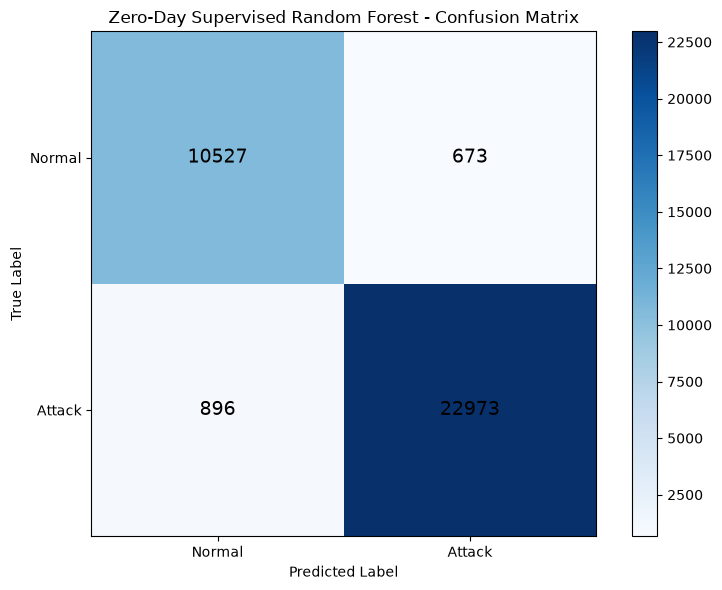

In [67]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val_zd_binary, y_val_zd_pred)

plt.figure(figsize=(8, 6))

plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("Zero-Day Supervised Random Forest - Confusion Matrix")
plt.colorbar()

classes = ["Normal", "Attack"]

plt.xticks([0, 1], classes)
plt.yticks([0, 1], classes)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Display values inside the matrix
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, format(cm[i, j], "d"),
            ha="center",
            va="center",
            color="black",
            fontsize=14
        )

plt.tight_layout()
plt.show()

In [68]:
import numpy as np
import pandas as pd
from sklearn.metrics import recall_score, f1_score

print("ZERO-DAY DETECTION BY ATTACK CATEGORY")
print("=" * 60)

# Convert validation attack categories to NumPy
y_val_categories = np.asarray(y_val_multi)

# Convert binary labels to NumPy
y_val_labels = np.asarray(y_val_zd_binary)

results = []

for category in held_out_categories:

    # Identify records belonging to this attack category
    mask = y_val_categories == category

    X_category = X_val_zd_processed[mask]
    y_category = y_val_labels[mask]

    if len(y_category) == 0:
        continue

    # Predict
    y_pred_category = zero_day_rf.predict(X_category)

    results.append({
        "Attack Category": category,
        "Records": len(y_category),
        "Detected": int(y_pred_category.sum()),
        "Detection Rate": recall_score(
            y_category, y_pred_category,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_category, y_pred_category,
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

ZERO-DAY DETECTION BY ATTACK CATEGORY
Attack Category  Records  Detected  Detection Rate  F1-score
       Exploits     6583      6433        0.977214  0.988476
 Reconnaissance     2135      2092        0.979859  0.989827


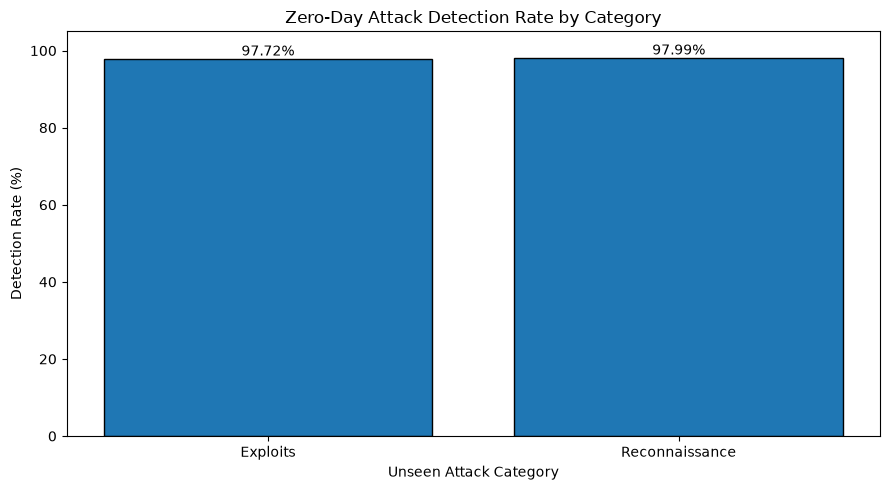

In [69]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

categories = results_df["Attack Category"]
rates = results_df["Detection Rate"] * 100

bars = plt.bar(
    categories,
    rates,
    edgecolor="black"
)

plt.title("Zero-Day Attack Detection Rate by Category")
plt.xlabel("Unseen Attack Category")
plt.ylabel("Detection Rate (%)")
plt.ylim(0, 105)

for bar, rate in zip(bars, rates):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{rate:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [70]:
import numpy as np
import pandas as pd

# Predictions for complete validation dataset
y_all_pred = zero_day_rf.predict(X_val_zd_processed)

y_categories = np.asarray(y_val_multi)
y_actual = np.asarray(y_val_zd_binary)

category_results = []

for category in sorted(np.unique(y_categories)):

    mask = y_categories == category

    actual = y_actual[mask]
    predicted = y_all_pred[mask]

    category_results.append({
        "Category": category,
        "Records": len(actual),
        "Detected as Attack": int(predicted.sum()),
        "Detection Rate (%)": round(
            predicted.mean() * 100, 2
        )
    })

category_results_df = pd.DataFrame(category_results)

print("DETECTION PERFORMANCE BY CATEGORY")
print("=" * 70)

print(category_results_df.to_string(index=False))

DETECTION PERFORMANCE BY CATEGORY
      Category  Records  Detected as Attack  Detection Rate (%)
      Analysis      422                 379               89.81
      Backdoor      314                 314              100.00
           DoS     2483                2480               99.88
      Exploits     6583                6433               97.72
       Fuzzers     3674                3024               82.31
       Generic     8005                8004               99.99
        Normal    11200                 673                6.01
Reconnaissance     2135                2092               97.99
     Shellcode      225                 219               97.33
         Worms       28                  28              100.00


ZERO-DAY MODEL CONFUSION MATRIX
[[10527   673]
 [  896 22973]]

Classification Report:
              precision    recall  f1-score   support

      Normal     0.9216    0.9399    0.9306     11200
      Attack     0.9715    0.9625    0.9670     23869

    accuracy                         0.9553     35069
   macro avg     0.9466    0.9512    0.9488     35069
weighted avg     0.9556    0.9553    0.9554     35069



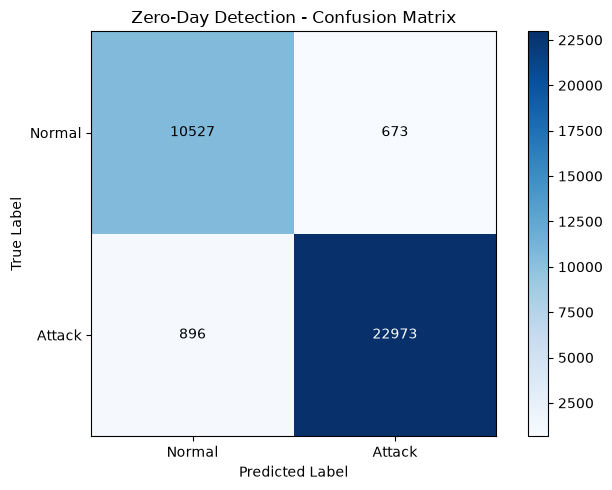

In [71]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)
import matplotlib.pyplot as plt
import numpy as np

y_true = np.asarray(y_val_zd_binary)
y_pred = zero_day_rf.predict(X_val_zd_processed)

cm = confusion_matrix(y_true, y_pred)

print("ZERO-DAY MODEL CONFUSION MATRIX")
print("=" * 50)

print(cm)

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Normal", "Attack"],
    digits=4
))

# Plot confusion matrix using Matplotlib only
plt.figure(figsize=(7, 5))

plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("Zero-Day Detection - Confusion Matrix")
plt.colorbar()

classes = ["Normal", "Attack"]

plt.xticks([0, 1], classes)
plt.yticks([0, 1], classes)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

threshold = cm.max() / 2

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, format(cm[i, j], "d"),
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black"
        )

plt.tight_layout()
plt.show()

ZERO-DAY ROC ANALYSIS
ROC-AUC Score: 0.9914


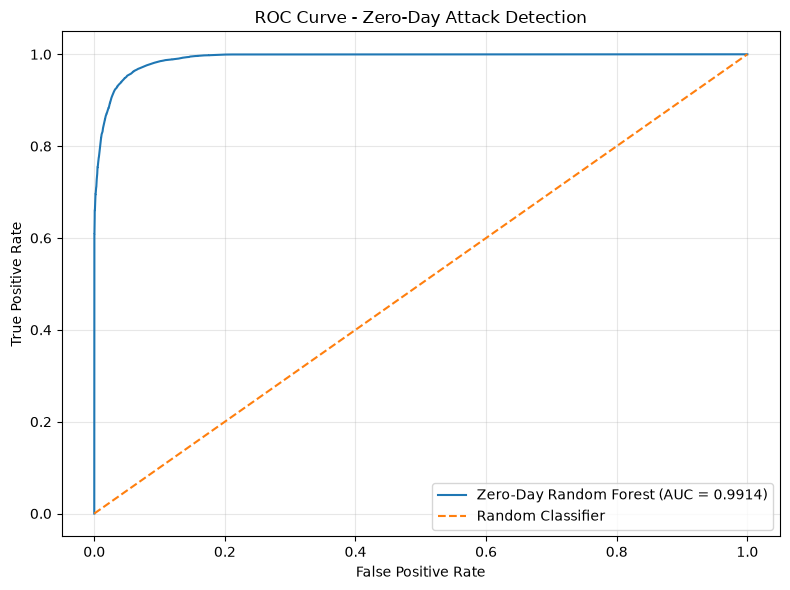

In [72]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get attack probabilities
y_prob = zero_day_rf.predict_proba(
    X_val_zd_processed
)[:, 1]

# Calculate ROC
fpr, tpr, thresholds = roc_curve(
    y_val_zd_binary,
    y_prob
)

auc_score = roc_auc_score(
    y_val_zd_binary,
    y_prob
)

print("ZERO-DAY ROC ANALYSIS")
print("=" * 50)
print(f"ROC-AUC Score: {auc_score:.4f}")

# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    fpr, tpr,
    label=f"Zero-Day Random Forest (AUC = {auc_score:.4f})"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Zero-Day Attack Detection")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

ZERO-DAY PRECISION-RECALL ANALYSIS
Average Precision (AP): 0.9956


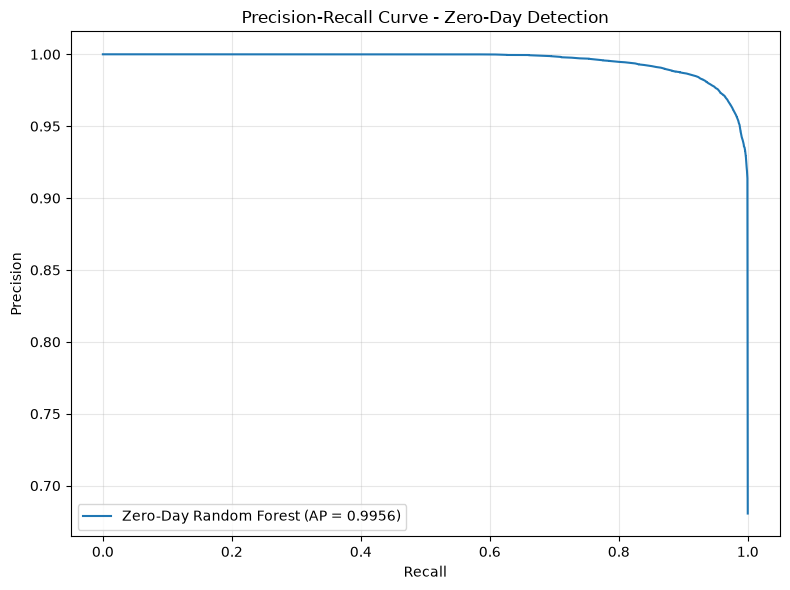

In [73]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)
import matplotlib.pyplot as plt

# Calculate precision-recall values
precision, recall, pr_thresholds = precision_recall_curve(
    y_val_zd_binary,
    y_prob
)

# Average precision
ap_score = average_precision_score(
    y_val_zd_binary,
    y_prob
)

print("ZERO-DAY PRECISION-RECALL ANALYSIS")
print("=" * 50)
print(f"Average Precision (AP): {ap_score:.4f}")

# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    label=f"Zero-Day Random Forest (AP = {ap_score:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Zero-Day Detection")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [74]:
import numpy as np
from sklearn.metrics import (
    precision_recall_curve,
    f1_score
)

# Validation attack categories
categories = np.asarray(y_val_multi)
labels = np.asarray(y_val_zd_binary)

# Identify known-category validation records
known_mask = ~np.isin(
    categories,
    held_out_categories
)

# Probability predictions
known_prob = y_prob[known_mask]
known_labels = labels[known_mask]

# Calculate threshold candidates
precision, recall, thresholds = precision_recall_curve(
    known_labels,
    known_prob
)

# Calculate F1 for each threshold
f1_values = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-10)
)

best_idx = np.argmax(f1_values)

best_threshold = thresholds[best_idx]

print("THRESHOLD OPTIMIZATION")
print("=" * 50)

print(f"Default threshold: 0.5000")
print(f"Optimal threshold: {best_threshold:.4f}")
print(f"Precision: {precision[best_idx]:.4f}")
print(f"Recall: {recall[best_idx]:.4f}")
print(f"F1-score: {f1_values[best_idx]:.4f}")

THRESHOLD OPTIMIZATION
Default threshold: 0.5000
Optimal threshold: 0.4767
Precision: 0.9510
Recall: 0.9599
F1-score: 0.9554


In [75]:
import numpy as np
from sklearn.metrics import recall_score

# Identify unseen attack records
unseen_mask = np.isin(
    categories,
    held_out_categories
)

y_unseen_true = labels[unseen_mask]
y_unseen_prob = y_prob[unseen_mask]

# Predictions using default threshold
pred_default = (y_unseen_prob >= 0.5).astype(int)

# Predictions using optimized threshold
pred_optimized = (
    y_unseen_prob >= best_threshold
).astype(int)

print("ZERO-DAY THRESHOLD COMPARISON")
print("=" * 60)

for name, predictions in [
    ("Default Threshold (0.5)", pred_default),
    ("Optimized Threshold", pred_optimized)
]:

    detected = int(predictions.sum())
    missed = len(predictions) - detected

    detection_rate = recall_score(
        y_unseen_true,
        predictions,
        zero_division=0
    )

    print(f"\n{name}")
    print("-" * 40)
    print("Unseen attacks:", len(predictions))
    print("Detected:", detected)
    print("Missed:", missed)
    print(f"Detection rate: {detection_rate * 100:.2f}%")

ZERO-DAY THRESHOLD COMPARISON

Default Threshold (0.5)
----------------------------------------
Unseen attacks: 8718
Detected: 8543
Missed: 175
Detection rate: 97.99%

Optimized Threshold
----------------------------------------
Unseen attacks: 8718
Detected: 8567
Missed: 151
Detection rate: 98.27%


In [76]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

y_true = np.asarray(y_val_zd_binary)

pred_default_all = (y_prob >= 0.5).astype(int)
pred_optimized_all = (y_prob >= best_threshold).astype(int)

print("OVERALL THRESHOLD COMPARISON")
print("=" * 65)

for name, pred in [
    ("Default Threshold (0.5)", pred_default_all),
    ("Optimized Threshold", pred_optimized_all)
]:

    tn, fp, fn, tp = confusion_matrix(
        y_true, pred
    ).ravel()

    print(f"\n{name}")
    print("-" * 45)

    print(f"Accuracy:  {accuracy_score(y_true, pred):.4f}")
    print(f"Precision: {precision_score(y_true, pred):.4f}")
    print(f"Recall:    {recall_score(y_true, pred):.4f}")
    print(f"F1-score:  {f1_score(y_true, pred):.4f}")
    print(f"False Positive Rate: {fp / (fp + tn):.4f}")

    print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

OVERALL THRESHOLD COMPARISON

Default Threshold (0.5)
---------------------------------------------
Accuracy:  0.9561
Precision: 0.9708
Recall:    0.9645
F1-score:  0.9676
False Positive Rate: 0.0619
TN=10507, FP=693, FN=847, TP=23022

Optimized Threshold
---------------------------------------------
Accuracy:  0.9570
Precision: 0.9686
Recall:    0.9682
F1-score:  0.9684
False Positive Rate: 0.0670
TN=10450, FP=750, FN=758, TP=23111


In [77]:
# Define optimized threshold from previous optimization
optimal_threshold = 0.4767

print("FINAL THRESHOLD CONSISTENCY CHECK")
print("=" * 60)

print("Selected threshold:", optimal_threshold)

print("\nUnseen attack detection using selected threshold:")

y_unseen_prob = zero_day_rf.predict_proba(
    X_val_unseen_processed
)[:, 1]

y_unseen_final = (
    y_unseen_prob >= optimal_threshold
).astype(int)

print("Total unseen attacks:", len(y_unseen_final))
print("Detected:", y_unseen_final.sum())
print("Missed:", len(y_unseen_final) - y_unseen_final.sum())

print(
    "Detection rate:",
    recall_score(y_val_unseen_binary, y_unseen_final) * 100
)

FINAL THRESHOLD CONSISTENCY CHECK
Selected threshold: 0.4767

Unseen attack detection using selected threshold:
Total unseen attacks: 8718
Detected: 8567
Missed: 151
Detection rate: 98.26795136499197


In [78]:
# OPTIMIZED ZERO-DAY DETECTION BY CATEGORY

category_results_optimized = []

for category in held_out_categories:

    mask = y_val_categories == category

    y_true_category = y_val_unseen_binary[
        y_val_categories[mask].index
    ] if hasattr(y_val_categories[mask], "index") else None

In [79]:
# OPTIMIZED ZERO-DAY DETECTION BY CATEGORY

category_results_optimized = []

# Get attack categories from full validation labels
unseen_categories = np.asarray(y_val_multi)

# Identify records belonging to held-out categories
heldout_mask = np.isin(
    unseen_categories,
    held_out_categories
)

# Extract categories for held-out validation records
unseen_categories = unseen_categories[heldout_mask]

for category in held_out_categories:

    mask = unseen_categories == category

    y_true_category = y_val_unseen_binary[mask]
    y_pred_category = y_unseen_final[mask]

    detected = int(y_pred_category.sum())
    total = len(y_true_category)

    detection_rate = (
        detected / total * 100 if total > 0 else 0
    )

    category_results_optimized.append({
        "Attack Category": category,
        "Records": total,
        "Detected": detected,
        "Missed": total - detected,
        "Detection Rate (%)": round(detection_rate, 2)
    })

optimized_category_df = pd.DataFrame(
    category_results_optimized
)

print("OPTIMIZED ZERO-DAY DETECTION BY CATEGORY")
print("=" * 60)

print(optimized_category_df.to_string(index=False))

OPTIMIZED ZERO-DAY DETECTION BY CATEGORY
Attack Category  Records  Detected  Missed  Detection Rate (%)
       Exploits     6583      6463     120               98.18
 Reconnaissance     2135      2104      31               98.55


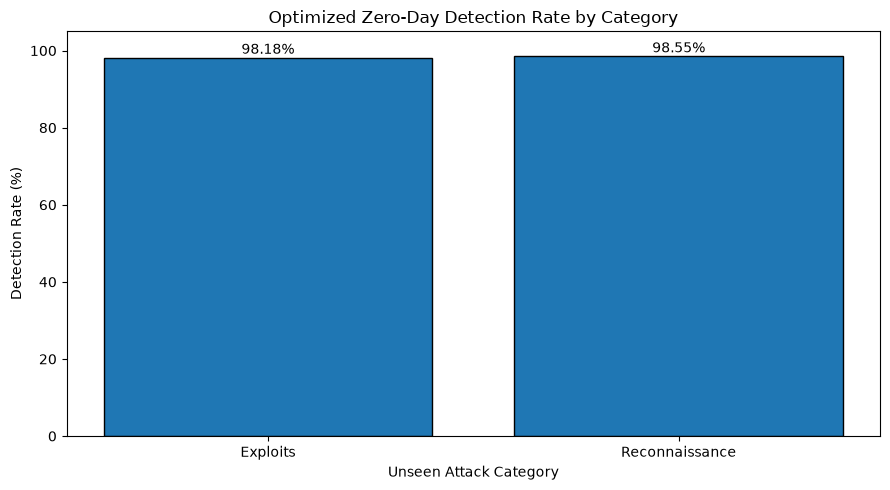

In [80]:
# OPTIMIZED ZERO-DAY DETECTION RATE VISUALIZATION

import matplotlib.pyplot as plt

categories = optimized_category_df["Attack Category"]
rates = optimized_category_df["Detection Rate (%)"]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    categories,
    rates,
    edgecolor="black"
)

plt.ylim(0, 105)
plt.ylabel("Detection Rate (%)")
plt.xlabel("Unseen Attack Category")
plt.title("Optimized Zero-Day Detection Rate by Category")

for bar, rate in zip(bars, rates):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{rate:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [81]:
# FINAL ZERO-DAY THRESHOLD COMPARISON

default_threshold = 0.5

default_predictions = (
    y_unseen_prob >= default_threshold
).astype(int)

optimized_predictions = (
    y_unseen_prob >= optimal_threshold
).astype(int)

total_unseen = len(y_val_unseen_binary)

comparison_results = []

for name, threshold, predictions in [
    ("Default", default_threshold, default_predictions),
    ("Optimized", optimal_threshold, optimized_predictions)
]:

    detected = int(predictions.sum())
    missed = total_unseen - detected

    comparison_results.append({
        "Threshold Type": name,
        "Threshold": threshold,
        "Total Unseen Attacks": total_unseen,
        "Detected": detected,
        "Missed": missed,
        "Detection Rate (%)": round(
            detected / total_unseen * 100, 2
        )
    })

threshold_comparison_df = pd.DataFrame(
    comparison_results
)

print("FINAL ZERO-DAY THRESHOLD COMPARISON")
print("=" * 70)

print(
    threshold_comparison_df.to_string(index=False)
)

FINAL ZERO-DAY THRESHOLD COMPARISON
Threshold Type  Threshold  Total Unseen Attacks  Detected  Missed  Detection Rate (%)
       Default     0.5000                  8718      8543     175               97.99
     Optimized     0.4767                  8718      8567     151               98.27


In [82]:
# EXPORT ZERO-DAY EVALUATION RESULTS

threshold_comparison_df.to_csv(
    "zero_day_threshold_comparison.csv",
    index=False
)

optimized_category_df.to_csv(
    "zero_day_category_results.csv",
    index=False
)

print("Evaluation results saved successfully.")

print("\nFiles created:")
print("1. zero_day_threshold_comparison.csv")
print("2. zero_day_category_results.csv")

Evaluation results saved successfully.

Files created:
1. zero_day_threshold_comparison.csv
2. zero_day_category_results.csv


In [83]:
print("ZERO-DAY MODEL AND PREPROCESSOR VARIABLES")
print("=" * 60)

for name in sorted(globals()):
    if any(word in name.lower() for word in [
        "preprocess", "transformer", "zero_day_rf"
    ]):
        obj = globals()[name]

        if hasattr(obj, "fit") or hasattr(obj, "predict"):
            print(name, ":", type(obj))

ZERO-DAY MODEL AND PREPROCESSOR VARIABLES
ColumnTransformer : <class 'abc.ABCMeta'>
anomaly_preprocessor : <class 'sklearn.compose._column_transformer.ColumnTransformer'>
preprocessor : <class 'sklearn.compose._column_transformer.ColumnTransformer'>
preprocessor_zd : <class 'sklearn.compose._column_transformer.ColumnTransformer'>
zero_day_rf : <class 'sklearn.ensemble._forest.RandomForestClassifier'>


In [84]:
import joblib

# Package model components
zero_day_bundle = {
    "model": zero_day_rf,
    "preprocessor": preprocessor_zd,
    "threshold": optimal_threshold,
    "held_out_categories": held_out_categories,
    "feature_count": 42,
    "processed_feature_count": 192
}

# Save complete model
joblib.dump(
    zero_day_bundle,
    "zero_day_detection_model.pkl"
)

print("Zero-day detection model saved successfully!")
print("File: zero_day_detection_model.pkl")
print("Threshold:", optimal_threshold)
print("Held-out categories:", held_out_categories)

Zero-day detection model saved successfully!
File: zero_day_detection_model.pkl
Threshold: 0.4767
Held-out categories: ['Exploits', 'Reconnaissance']


In [85]:
# TEST SAVED ZERO-DAY MODEL

import joblib
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Load saved model bundle
loaded_bundle = joblib.load(
    "zero_day_detection_model.pkl"
)

loaded_model = loaded_bundle["model"]
loaded_preprocessor = loaded_bundle["preprocessor"]
loaded_threshold = loaded_bundle["threshold"]

# Process unseen attack validation data
X_unseen_loaded_processed = loaded_preprocessor.transform(
    X_val_unseen
)

# Generate predictions
loaded_probabilities = loaded_model.predict_proba(
    X_unseen_loaded_processed
)[:, 1]

loaded_predictions = (
    loaded_probabilities >= loaded_threshold
).astype(int)

print("SAVED MODEL TEST RESULTS")
print("=" * 60)

print("Model loaded successfully!")
print("Threshold:", loaded_threshold)
print("Records tested:", len(loaded_predictions))

print("Accuracy:",
      accuracy_score(y_val_unseen_binary, loaded_predictions))

print("Precision:",
      precision_score(y_val_unseen_binary, loaded_predictions))

print("Recall:",
      recall_score(y_val_unseen_binary, loaded_predictions))

print("F1-score:",
      f1_score(y_val_unseen_binary, loaded_predictions))

SAVED MODEL TEST RESULTS
Model loaded successfully!
Threshold: 0.4767
Records tested: 8718
Accuracy: 0.9826795136499197
Precision: 1.0
Recall: 0.9826795136499197
F1-score: 0.9912641018223893


In [86]:
# REUSABLE ZERO-DAY ATTACK DETECTION FUNCTION

def detect_zero_day_attack(input_data):

    # Apply saved preprocessing
    processed_data = loaded_preprocessor.transform(input_data)

    # Get attack probability
    probabilities = loaded_model.predict_proba(
        processed_data
    )[:, 1]

    # Apply optimized threshold
    predictions = (
        probabilities >= loaded_threshold
    ).astype(int)

    results = pd.DataFrame({
        "Prediction": predictions,
        "Result": [
            "Attack / Suspicious" if p == 1 else "Normal"
            for p in predictions
        ],
        "Attack Probability (%)": (
            probabilities * 100
        ).round(2)
    })

    return results


print("Zero-day detection function created successfully.")

Zero-day detection function created successfully.


In [87]:
# TEST ZERO-DAY DETECTOR ON REAL DATASET RECORDS

sample_records = X_val_unseen.iloc[:10]

sample_predictions = detect_zero_day_attack(
    sample_records
)

print("ZERO-DAY DETECTION SAMPLE TEST")
print("=" * 60)

print("Records tested:", len(sample_records))
print("\nPredictions:")

print(
    sample_predictions.to_string(index=False)
)

ZERO-DAY DETECTION SAMPLE TEST
Records tested: 10

Predictions:
 Prediction              Result  Attack Probability (%)
          1 Attack / Suspicious                   100.0
          1 Attack / Suspicious                    98.0
          1 Attack / Suspicious                    95.0
          1 Attack / Suspicious                    50.0
          1 Attack / Suspicious                    88.0
          1 Attack / Suspicious                   100.0
          1 Attack / Suspicious                    74.0
          1 Attack / Suspicious                    87.0
          1 Attack / Suspicious                   100.0
          1 Attack / Suspicious                   100.0


In [88]:
# COMPLETE VALIDATION — ZERO-DAY DETECTOR

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Use the correct validation target
y_full_val = y_val_zd_binary

# Transform complete validation data
X_full_val_processed = loaded_preprocessor.transform(X_val)

# Predict probabilities
full_val_probabilities = loaded_model.predict_proba(
    X_full_val_processed
)[:, 1]

# Apply optimized threshold
full_val_predictions = (
    full_val_probabilities >= loaded_threshold
).astype(int)

print("COMPLETE VALIDATION — ZERO-DAY DETECTOR")
print("=" * 60)

print("Threshold:", loaded_threshold)
print("Total records:", len(y_full_val))

print("Accuracy:",
      accuracy_score(y_full_val, full_val_predictions))

print("Precision:",
      precision_score(y_full_val, full_val_predictions))

print("Recall:",
      recall_score(y_full_val, full_val_predictions))

print("F1-score:",
      f1_score(y_full_val, full_val_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_full_val, full_val_predictions))

print("\nClassification Report:")
print(classification_report(
    y_full_val,
    full_val_predictions,
    target_names=["Normal", "Attack"]
))

COMPLETE VALIDATION — ZERO-DAY DETECTOR
Threshold: 0.4767
Total records: 35069
Accuracy: 0.9569990589979754
Precision: 0.9685679560789573
Recall: 0.9682433281662407
F1-score: 0.9684056149172429

Confusion Matrix:
[[10450   750]
 [  758 23111]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.93      0.93      0.93     11200
      Attack       0.97      0.97      0.97     23869

    accuracy                           0.96     35069
   macro avg       0.95      0.95      0.95     35069
weighted avg       0.96      0.96      0.96     35069



In [89]:
# EXPORT COMPLETE ZERO-DAY VALIDATION PREDICTIONS

final_results_df = pd.DataFrame({
    "Actual_Category": np.asarray(y_val_multi),
    "Actual_Binary_Label": np.asarray(y_full_val),
    "Predicted_Binary_Label": full_val_predictions,
    "Attack_Probability": full_val_probabilities,
    "Prediction": [
        "Attack / Suspicious" if p == 1 else "Normal"
        for p in full_val_predictions
    ]
})

final_results_df.to_csv(
    "zero_day_complete_validation_predictions.csv",
    index=False
)

print("Final validation predictions exported successfully!")
print("Records:", len(final_results_df))
print("File: zero_day_complete_validation_predictions.csv")

display(final_results_df.head(10))

Final validation predictions exported successfully!
Records: 35069
File: zero_day_complete_validation_predictions.csv


,Actual_Category,Actual_Binary_Label,Predicted_Binary_Label,Attack_Probability,Prediction
0,DoS,1,1,0.83,Attack / Suspicious
1,Exploits,1,1,1.00,Attack / Suspicious
2,Reconnaissance,1,1,0.98,Attack / Suspicious
3,Exploits,1,1,0.95,Attack / Suspicious
4,DoS,1,1,1.00,Attack / Suspicious
5,Exploits,1,1,0.50,Attack / Suspicious
6,Fuzzers,1,1,0.79,Attack / Suspicious
7,Generic,1,1,1.00,Attack / Suspicious
8,Generic,1,1,1.00,Attack / Suspicious
9,Exploits,1,1,0.88,Attack / Suspicious


In [90]:
# FINAL ZERO-DAY PREDICTION ANALYSIS

print("FINAL ZERO-DAY PREDICTION ANALYSIS")
print("=" * 60)

# Overall prediction correctness
correct = (
    final_results_df["Actual_Binary_Label"]
    == final_results_df["Predicted_Binary_Label"]
)

print("Total records:", len(final_results_df))
print("Correct predictions:", correct.sum())
print("Incorrect predictions:", (~correct).sum())

print("Overall accuracy:",
      round(correct.mean() * 100, 2), "%")

print("\nPrediction distribution:")
print(final_results_df["Prediction"].value_counts())

# Performance by actual attack category
category_summary = final_results_df.groupby(
    "Actual_Category"
).apply(
    lambda group: pd.Series({
        "Records": len(group),
        "Correct": (
            group["Actual_Binary_Label"]
            == group["Predicted_Binary_Label"]
        ).sum(),
        "Accuracy (%)": round(
            (
                group["Actual_Binary_Label"]
                == group["Predicted_Binary_Label"]
            ).mean() * 100,
            2
        )
    }),
    include_groups=False
)

print("\nPER-CATEGORY VALIDATION SUMMARY")
print("=" * 60)

display(category_summary.sort_values(
    "Accuracy (%)",
    ascending=False
))

FINAL ZERO-DAY PREDICTION ANALYSIS
Total records: 35069
Correct predictions: 33561
Incorrect predictions: 1508
Overall accuracy: 95.7 %

Prediction distribution:
Prediction
Attack / Suspicious    23861
Normal                 11208
Name: count, dtype: int64

PER-CATEGORY VALIDATION SUMMARY


,Records,Correct,Accuracy (%)
Actual_Category,,,
Backdoor,314.0,314.0,100.00
Generic,8005.0,8005.0,100.00
Worms,28.0,28.0,100.00
DoS,2483.0,2481.0,99.92
Reconnaissance,2135.0,2104.0,98.55
Exploits,6583.0,6463.0,98.18
Shellcode,225.0,220.0,97.78
Normal,11200.0,10450.0,93.30
Analysis,422.0,381.0,90.28


In [91]:
# EXPORT FINAL CATEGORY-WISE ANALYSIS

category_summary.to_csv(
    "zero_day_final_category_analysis.csv"
)

print("Final category analysis saved successfully!")
print("File: zero_day_final_category_analysis.csv")

print("\nFinal category-wise accuracy:")
display(category_summary)

Final category analysis saved successfully!
File: zero_day_final_category_analysis.csv

Final category-wise accuracy:


,Records,Correct,Accuracy (%)
Actual_Category,,,
Analysis,422.0,381.0,90.28
Backdoor,314.0,314.0,100.00
DoS,2483.0,2481.0,99.92
Exploits,6583.0,6463.0,98.18
Fuzzers,3674.0,3115.0,84.78
Generic,8005.0,8005.0,100.00
Normal,11200.0,10450.0,93.30
Reconnaissance,2135.0,2104.0,98.55
Shellcode,225.0,220.0,97.78


In [92]:
# FINAL MODEL COMPARISON

final_model_comparison = pd.DataFrame([
    {
        "Model": "Supervised Random Forest",
        "Accuracy": 0.9591,
        "Precision": 0.9632,
        "Recall": 0.9772,
        "F1-score": 0.9702
    },
    {
        "Model": "Isolation Forest",
        "Accuracy": 0.3942,
        "Precision": 0.9623,
        "Recall": 0.1144,
        "F1-score": 0.2045
    },
    {
        "Model": "Hybrid Detection",
        "Accuracy": 0.9561,
        "Precision": 0.9590,
        "Recall": 0.9772,
        "F1-score": 0.9680
    },
    {
        "Model": "Zero-Day Random Forest",
        "Accuracy": 0.9553,
        "Precision": 0.9715,
        "Recall": 0.9625,
        "F1-score": 0.9669
    }
])

print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 65)

display(final_model_comparison)

final_model_comparison.to_csv(
    "final_model_comparison.csv",
    index=False
)

print("Comparison saved: final_model_comparison.csv")

FINAL MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-score
0,Supervised Random Forest,0.9591,0.9632,0.9772,0.9702
1,Isolation Forest,0.3942,0.9623,0.1144,0.2045
2,Hybrid Detection,0.9561,0.9590,0.9772,0.9680
3,Zero-Day Random Forest,0.9553,0.9715,0.9625,0.9669


Comparison saved: final_model_comparison.csv


In [93]:
import os

print("PROJECT FILES")
print("=" * 50)

for file in sorted(os.listdir(".")):
    if file.endswith((".pkl", ".csv", ".py")):
        print(file)

PROJECT FILES
app.py
app_backup.py
app_before_restore.py
app_recovered.py
attack_category_model.pkl
final_model_comparison.csv
model_comparison.csv
network_traffic_detection_report.csv
network_traffic_test.csv
zero_day_category_results.csv
zero_day_complete_validation_predictions.csv
zero_day_detection_model.pkl
zero_day_final_category_analysis.csv
zero_day_threshold_comparison.csv


In [94]:
import joblib
import os

model_path = "zero_day_detection_model.pkl"

# Inspect file signature
with open(model_path, "rb") as f:
    print("File signature:", f.read(10))

# Load using joblib
try:
    saved_object = joblib.load(model_path)

    print("\nModel loaded successfully!")
    print("Object type:", type(saved_object))

except Exception as e:
    print("\nLoading failed:")
    print(type(e).__name__, e)

File signature: b'\x80\x04\x95\xa1\x03\x00\x00\x00\x00\x00'

Model loaded successfully!
Object type: <class 'dict'>


In [95]:
print("SAVED MODEL DICTIONARY")
print("=" * 60)

for key, value in saved_object.items():
    print(f"\nKey: {key}")
    print("Type:", type(value))

    if hasattr(value, "shape"):
        print("Shape:", value.shape)

    elif hasattr(value, "predict"):
        print("Prediction method: Available")

    elif hasattr(value, "transform"):
        print("Transformation method: Available")

    else:
        print("Value:", value)

SAVED MODEL DICTIONARY

Key: model
Type: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
Prediction method: Available

Key: preprocessor
Type: <class 'sklearn.compose._column_transformer.ColumnTransformer'>
Transformation method: Available

Key: threshold
Type: <class 'float'>
Value: 0.4767

Key: held_out_categories
Type: <class 'list'>
Value: ['Exploits', 'Reconnaissance']

Key: feature_count
Type: <class 'int'>
Value: 42

Key: processed_feature_count
Type: <class 'int'>
Value: 192


In [96]:
import pandas as pd
import numpy as np

# Extract saved components
zero_day_model = saved_object["model"]
zero_day_preprocessor = saved_object["preprocessor"]
zero_day_threshold = saved_object["threshold"]

def detect_zero_day(network_data):

    # Validate input
    if not isinstance(network_data, pd.DataFrame):
        raise TypeError("Input must be a pandas DataFrame.")

    if network_data.shape[1] != saved_object["feature_count"]:
        raise ValueError(
            f"Expected 42 features, received {network_data.shape[1]}"
        )

    # Apply saved preprocessing
    processed_data = zero_day_preprocessor.transform(network_data)

    # Calculate attack probabilities
    attack_probabilities = zero_day_model.predict_proba(
        processed_data
    )[:, 1]

    # Apply optimized threshold
    predictions = (
        attack_probabilities >= zero_day_threshold
    ).astype(int)

    # Generate results
    results = pd.DataFrame({
        "Prediction": predictions,
        "Attack_Probability": attack_probabilities,
        "Result": [
            "Attack / Suspicious" if p == 1 else "Normal"
            for p in predictions
        ]
    })

    return results


print("Zero-day detection function created successfully!")
print("Threshold:", zero_day_threshold)

Zero-day detection function created successfully!
Threshold: 0.4767


In [97]:
# Test using validation records
test_data = X_val.iloc[:10].copy()

test_results = detect_zero_day(test_data)

print("ZERO-DAY DETECTION TEST")
print("=" * 50)

display(test_results)

ZERO-DAY DETECTION TEST


,Prediction,Attack_Probability,Result
0,1,0.83,Attack / Suspicious
1,1,1.00,Attack / Suspicious
2,1,0.98,Attack / Suspicious
3,1,0.95,Attack / Suspicious
4,1,1.00,Attack / Suspicious
5,1,0.50,Attack / Suspicious
6,1,0.79,Attack / Suspicious
7,1,1.00,Attack / Suspicious
8,1,1.00,Attack / Suspicious
9,1,0.88,Attack / Suspicious


In [98]:
# TEST NORMAL TRAFFIC

normal_mask = y_val_zd_binary == 0

normal_test_data = X_val.loc[normal_mask].iloc[:10].copy()

normal_test_results = detect_zero_day(normal_test_data)

print("NORMAL TRAFFIC TEST")
print("=" * 50)

display(normal_test_results)

print("\nNormal records detected as Normal:",
      (normal_test_results["Prediction"] == 0).sum(), "/ 10")

print("Normal records flagged as Attack:",
      (normal_test_results["Prediction"] == 1).sum(), "/ 10")

NORMAL TRAFFIC TEST


,Prediction,Attack_Probability,Result
0,0,0.00,Normal
1,0,0.39,Normal
2,0,0.00,Normal
3,0,0.25,Normal
4,0,0.34,Normal
5,1,0.61,Attack / Suspicious
6,1,0.52,Attack / Suspicious
7,0,0.00,Normal
8,0,0.00,Normal
9,0,0.30,Normal



Normal records detected as Normal: 8 / 10
Normal records flagged as Attack: 2 / 10


In [99]:
# CREATE SAMPLE CSV FOR BATCH TESTING

sample_csv = X_val.iloc[:100].copy()

sample_csv.to_csv(
    "network_traffic_test.csv",
    index=False
)

print("Sample network traffic CSV created!")
print("File: network_traffic_test.csv")
print("Records:", len(sample_csv))
print("Features:", sample_csv.shape[1])

Sample network traffic CSV created!
File: network_traffic_test.csv
Records: 100
Features: 42


In [100]:
# CSV-BASED BATCH DETECTION

uploaded_data = pd.read_csv(
    "network_traffic_test.csv"
)

batch_results = detect_zero_day(uploaded_data)

# Combine original data with predictions
batch_report = uploaded_data.copy()

batch_report["Prediction"] = batch_results["Prediction"]
batch_report["Attack_Probability"] = batch_results["Attack_Probability"]
batch_report["Result"] = batch_results["Result"]

print("BATCH DETECTION REPORT")
print("=" * 60)

print("Total records:", len(batch_report))
print("Normal:", (batch_report["Prediction"] == 0).sum())
print("Suspicious:", (batch_report["Prediction"] == 1).sum())

display(batch_report.head(10))

BATCH DETECTION REPORT
Total records: 100
Normal: 26
Suspicious: 74


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,...,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,Prediction,Attack_Probability,Result
0,1.959922,tcp,http,FIN,10,10,864,1754,9.694264e+00,254,...,2,0,0,1,1,1,0,1,0.83,Attack / Suspicious
1,0.000008,sun-nd,-,INT,2,0,200,0,1.250000e+05,254,...,2,0,0,0,1,2,0,1,1.00,Attack / Suspicious
2,0.000001,udp,-,INT,2,0,168,0,1.000000e+06,254,...,1,0,0,0,1,1,0,1,0.98,Attack / Suspicious
3,0.948013,tcp,http,FIN,12,10,1296,2844,2.215160e+01,62,...,1,0,0,1,1,1,0,1,0.95,Attack / Suspicious
4,0.000006,unas,-,INT,2,0,200,0,1.666667e+05,254,...,14,0,0,0,5,12,0,1,1.00,Attack / Suspicious
5,1.082475,tcp,ftp,FIN,20,22,1096,1664,3.787617e+01,62,...,2,1,1,0,2,1,0,1,0.50,Attack / Suspicious
6,2.070405,tcp,-,FIN,172,30,217655,1300,9.708245e+01,254,...,2,0,0,0,3,2,0,1,0.79,Attack / Suspicious
7,0.000007,udp,dns,INT,2,0,114,0,1.428571e+05,254,...,13,0,0,0,11,10,0,1,1.00,Attack / Suspicious
8,0.000006,udp,dns,INT,2,0,114,0,1.666667e+05,254,...,27,0,0,0,14,27,0,1,1.00,Attack / Suspicious
9,0.649982,tcp,ftp,FIN,10,8,2524,608,2.615457e+01,254,...,1,0,0,0,2,1,0,1,0.88,Attack / Suspicious


In [101]:
batch_report.to_csv(
    "network_traffic_detection_report.csv",
    index=False
)

print("Detection report exported successfully!")
print("File: network_traffic_detection_report.csv")

Detection report exported successfully!
File: network_traffic_detection_report.csv


In [102]:
!streamlit --version

Streamlit, version 1.66.1


In [103]:
import requests

try:
    response = requests.get("http://localhost:8501", timeout=5)
    print("Streamlit is responding!")
    print("Status code:", response.status_code)
except Exception as e:
    print("Streamlit is not responding:")
    print(e)

Streamlit is not responding:
HTTPConnectionPool(host='localhost', port=8501): Max retries exceeded with url: / (Caused by NewConnectionError("HTTPConnection(host='localhost', port=8501): Failed to establish a new connection: [WinError 10061] No connection could be made because the target machine actively refused it"))


In [104]:
import os

print("Current notebook folder:")
print(os.getcwd())

print("\nFiles available in this folder:")
print(os.listdir())

Current notebook folder:
E:\New folder\Major Proj\Zero Day attack\Jupyter

Files available in this folder:
['ZD.ipynb', '.ipynb_checkpoints', 'Dataset', 'zero_day_threshold_comparison.csv', 'zero_day_category_results.csv', 'zero_day_detection_model.pkl', 'zero_day_complete_validation_predictions.csv', 'zero_day_final_category_analysis.csv', 'final_model_comparison.csv', 'network_traffic_test.csv', 'network_traffic_detection_report.csv', 'app.py', 'attack_category_model.pkl', 'model_comparison.csv', 'app_backup.py', 'test123.txt', 'app_recovered.py', 'app_before_restore.py', 'anaconda_projects', '.virtual_documents', 'Untitled.ipynb', 'EDA_Attack_Category_Distribution.png', 'EDA_Traffic_Donut_Chart.png', 'EDA_Correlation_Heatmap.png', 'EDA_Normal_vs_Attack_Features.png', 'EDA_Attack_Category_Treemap.html', 'EDA_Attack_Category_Radar.png', 'EDA_Protocol_Distribution.png', 'EDA_Protocol_Traffic_Composition.png', 'EDA_Service_Traffic_Composition.png', 'EDA_Protocol_Attack_Category_Heatmap.

In [105]:
import os

print(os.listdir("Dataset"))

['NUSW-NB15_features.csv', 'UNSW_NB15_testing-set.csv', 'UNSW_NB15_training-set.csv']


In [106]:
import pandas as pd

training_data = pd.read_csv("Dataset/UNSW_NB15_training-set.csv")

print("Dataset shape:", training_data.shape)

print("\nAvailable columns:")
print(training_data.columns.tolist())

print("\nAttack category distribution:")
print(training_data["attack_cat"].value_counts())

Dataset shape: (175341, 45)

Available columns:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']

Attack category distribution:
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


In [107]:
print("Training features:", X_train.shape)
print("Training categories:", y_train_multiclass.shape)

print("\nTraining target categories:")
print(y_train_multiclass.value_counts())

print("\nValidation features:", X_val.shape)
print("Validation categories:", y_val_multi.shape)

Training features: (175341, 42)
Training categories: (175341,)

Training target categories:
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

Validation features: (35069, 42)
Validation categories: (35069,)


In [108]:
print("X_train type:", type(X_train))
print("X_train_processed shape:", X_train_processed.shape)

print("\nMulticlass labels:", y_train_multiclass.shape)
print("Processed training data:", X_train_processed.shape)

print("\nPreprocessor available:", "preprocessor" in globals())
print("zero_day_preprocessor available:", "zero_day_preprocessor" in globals())

X_train type: <class 'pandas.DataFrame'>
X_train_processed shape: (140272, 192)

Multiclass labels: (175341,)
Processed training data: (140272, 192)

Preprocessor available: True
zero_day_preprocessor available: True


In [109]:
print("Available training label variables:")

for name in globals():
    if "y_train" in name.lower() or "y_zero" in name.lower():
        value = globals()[name]

        if hasattr(value, "shape"):
            print(name, "→", value.shape)

print("\nInspect y_train_split:")
print("Shape:", y_train_split.shape)
print("Unique values:", pd.Series(y_train_split).unique()[:20])
print("Value counts:")
print(pd.Series(y_train_split).value_counts())

Available training label variables:
y_train_binary → (175341,)
y_train_multiclass → (175341,)
y_train_split → (140272,)
y_train_multi_split → (140272,)
X_anomaly_train → (44800, 42)
y_train_zd → (105106,)

Inspect y_train_split:
Shape: (140272,)
Unique values: [1 0]
Value counts:
label
1    95472
0    44800
Name: count, dtype: int64


In [110]:
print("Multiclass training labels:")
print("Shape:", y_train_multi_split.shape)

print("\nCategories:")
print(pd.Series(y_train_multi_split).unique())

print("\nCategory distribution:")
print(pd.Series(y_train_multi_split).value_counts())

Multiclass training labels:
Shape: (140272,)

Categories:
<ArrowStringArray>
[      'Exploits',         'Normal',       'Analysis',        'Generic',
 'Reconnaissance',        'Fuzzers',            'DoS',      'Shellcode',
       'Backdoor',          'Worms']
Length: 10, dtype: str

Category distribution:
attack_cat
Normal            44800
Generic           31995
Exploits          26810
Fuzzers           14510
DoS                9781
Reconnaissance     8356
Analysis           1578
Backdoor           1432
Shellcode           908
Worms               102
Name: count, dtype: int64


In [111]:
from sklearn.ensemble import RandomForestClassifier
import time

print("TRAINING ATTACK CATEGORY CLASSIFIER")
print("=" * 60)

attack_category_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

attack_category_model.fit(
    X_train_processed,
    y_train_multi_split
)

training_time = time.time() - start_time

print("\nTraining completed successfully!")
print(f"Training time: {training_time:.2f} seconds")
print("Training records:", X_train_processed.shape[0])
print("Attack categories:", len(attack_category_model.classes_))
print("Categories:", attack_category_model.classes_)

TRAINING ATTACK CATEGORY CLASSIFIER

Training completed successfully!
Training time: 86.34 seconds
Training records: 140272
Attack categories: 10
Categories: ['Analysis' 'Backdoor' 'DoS' 'Exploits' 'Fuzzers' 'Generic' 'Normal'
 'Reconnaissance' 'Shellcode' 'Worms']


In [112]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("EVALUATING ATTACK CATEGORY CLASSIFIER")
print("=" * 60)

category_predictions = attack_category_model.predict(
    X_val_processed
)

category_accuracy = accuracy_score(
    y_val_multi,
    category_predictions
)

print(f"\nValidation Accuracy: {category_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_val_multi,
        category_predictions,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_val_multi,
        category_predictions,
        labels=attack_category_model.classes_
    )
)

EVALUATING ATTACK CATEGORY CLASSIFIER

Validation Accuracy: 76.10%

Classification Report:
                precision    recall  f1-score   support

      Analysis       0.06      0.20      0.09       422
      Backdoor       0.02      0.20      0.04       314
           DoS       0.30      0.20      0.24      2483
      Exploits       0.85      0.54      0.66      6583
       Fuzzers       0.67      0.87      0.76      3674
       Generic       1.00      0.98      0.99      8005
        Normal       0.98      0.86      0.92     11200
Reconnaissance       0.87      0.78      0.82      2135
     Shellcode       0.59      0.79      0.67       225
         Worms       0.55      0.64      0.59        28

      accuracy                           0.76     35069
     macro avg       0.59      0.61      0.58     35069
  weighted avg       0.85      0.76      0.79     35069


Confusion Matrix:
[[  84  170  128   22    2    0   16    0    0    0]
 [ 105   62  123   14    3    0    1    4    2    

In [113]:
print("Preprocessor type:", type(preprocessor))

print("\nTraining feature shape:", X_train_processed.shape)
print("Validation feature shape:", X_val_processed.shape)

print("\nPreprocessor output features:",
      preprocessor.transform(X_val).shape[1])

Preprocessor type: <class 'sklearn.compose._column_transformer.ColumnTransformer'>

Training feature shape: (140272, 192)
Validation feature shape: (35069, 192)

Preprocessor output features: 192


In [114]:
import joblib

attack_category_bundle = {
    "model": attack_category_model,
    "preprocessor": preprocessor,
    "categories": attack_category_model.classes_,
    "feature_count": X_train.shape[1]
}

joblib.dump(
    attack_category_bundle,
    "attack_category_model.pkl"
)

print("Attack category model saved successfully!")
print("File: attack_category_model.pkl")
print("Raw input features:", X_train.shape[1])
print("Processed features:", X_train_processed.shape[1])

Attack category model saved successfully!
File: attack_category_model.pkl
Raw input features: 42
Processed features: 192


In [115]:
import os
import joblib

print("Zero-day model exists:",
      os.path.exists("zero_day_detection_model.pkl"))

print("Attack category model exists:",
      os.path.exists("attack_category_model.pkl"))

category_bundle = joblib.load("attack_category_model.pkl")

print("\nCategory model loaded successfully!")
print("Categories:", category_bundle["categories"])
print("Feature count:", category_bundle["feature_count"])

Zero-day model exists: True
Attack category model exists: True

Category model loaded successfully!
Categories: ['Analysis' 'Backdoor' 'DoS' 'Exploits' 'Fuzzers' 'Generic' 'Normal'
 'Reconnaissance' 'Shellcode' 'Worms']
Feature count: 42


In [116]:
import pandas as pd
import joblib

# Load both saved models
zero_day_bundle = joblib.load("zero_day_detection_model.pkl")
category_bundle = joblib.load("attack_category_model.pkl")

# Use 10 validation records
test_data = X_val.iloc[:10].copy()

# Zero-day detection
zero_processed = zero_day_bundle["preprocessor"].transform(test_data)
zero_probabilities = zero_day_bundle["model"].predict_proba(
    zero_processed
)[:, 1]

zero_predictions = (
    zero_probabilities >= zero_day_bundle["threshold"]
).astype(int)

# Attack category classification
category_processed = category_bundle["preprocessor"].transform(test_data)
category_predictions = category_bundle["model"].predict(
    category_processed
)

# Combined results
combined_results = pd.DataFrame({
    "Zero_Day_Result": [
        "Attack / Suspicious" if p == 1 else "Normal"
        for p in zero_predictions
    ],
    "Attack_Probability": zero_probabilities,
    "Predicted_Category": category_predictions
})

display(combined_results)

,Zero_Day_Result,Attack_Probability,Predicted_Category
0,Attack / Suspicious,0.83,Exploits
1,Attack / Suspicious,1.00,DoS
2,Attack / Suspicious,0.98,Reconnaissance
3,Attack / Suspicious,0.95,Exploits
4,Attack / Suspicious,1.00,Analysis
5,Attack / Suspicious,0.50,Exploits
6,Attack / Suspicious,0.79,Fuzzers
7,Attack / Suspicious,1.00,Generic
8,Attack / Suspicious,1.00,Generic
9,Attack / Suspicious,0.88,Exploits


In [117]:
%whos

Variable                            Type                      Data/Info
-----------------------------------------------------------------------
ColumnTransformer                   ABCMeta                   <class 'sklearn.compose._<...>ormer.ColumnTransformer'>
ConfusionMatrixDisplay              type                      <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
IsolationForest                     ABCMeta                   <class 'sklearn.ensemble.<...>iforest.IsolationForest'>
OneHotEncoder                       type                      <class 'sklearn.preproces<...>_encoders.OneHotEncoder'>
RandomForestClassifier              ABCMeta                   <class 'sklearn.ensemble.<...>.RandomForestClassifier'>
X_anomaly_calibration               DataFrame                 Shape: (8960, 42)
X_anomaly_calibration_processed     ndarray                   8960x63: 564480 elems, type `float64`, 4515840 bytes (4.306640625 Mb)
X_anomaly_fit                       DataFrame         

In [118]:
print("Testing dataset shape:", test_df.shape)

print("\nAttack category distribution:")
print(test_df["attack_cat"].value_counts())

print("\nHeld-out categories:")
print(
    test_df[
        test_df["attack_cat"].isin(["Exploits", "Reconnaissance"])
    ]["attack_cat"].value_counts()
)

Testing dataset shape: (82332, 45)

Attack category distribution:
attack_cat
Normal            37000
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms                44
Name: count, dtype: int64

Held-out categories:
attack_cat
Exploits          11132
Reconnaissance     3496
Name: count, dtype: int64


In [119]:
import pandas as pd
import numpy as np
import joblib

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Load saved zero-day model
bundle = joblib.load("zero_day_detection_model.pkl")

model = bundle["model"]
preprocessor = bundle["preprocessor"]
threshold = bundle["threshold"]

# Get the exact feature columns expected by the model
features = list(preprocessor.feature_names_in_)

# Prepare test data
X_test_zero_day = test_df[features].copy()

# Transform and predict
X_test_processed = preprocessor.transform(X_test_zero_day)

probabilities = model.predict_proba(X_test_processed)[:, 1]

predictions = (probabilities >= threshold).astype(int)

# Store results
zero_day_test_results = test_df[["attack_cat", "label"]].copy()

zero_day_test_results["Predicted"] = predictions
zero_day_test_results["Attack_Probability"] = probabilities

# ----------------------------------------
# HELD-OUT ATTACK DETECTION
# ----------------------------------------

held_out_categories = ["Exploits", "Reconnaissance"]

print("ZERO-DAY DETECTION PERFORMANCE")
print("=" * 50)

for category in held_out_categories:

    category_data = zero_day_test_results[
        zero_day_test_results["attack_cat"] == category
    ]

    detected = int((category_data["Predicted"] == 1).sum())
    missed = int((category_data["Predicted"] == 0).sum())

    detection_rate = (
        detected / len(category_data) * 100
        if len(category_data) > 0 else 0
    )

    print(f"\nCategory: {category}")
    print(f"Total records: {len(category_data)}")
    print(f"Detected: {detected}")
    print(f"Missed: {missed}")
    print(f"Detection rate: {detection_rate:.2f}%")

# ----------------------------------------
# COMBINED HELD-OUT ATTACK PERFORMANCE
# ----------------------------------------

held_out_data = zero_day_test_results[
    zero_day_test_results["attack_cat"].isin(held_out_categories)
]

held_out_detected = int(
    (held_out_data["Predicted"] == 1).sum()
)

held_out_missed = int(
    (held_out_data["Predicted"] == 0).sum()
)

held_out_detection_rate = (
    held_out_detected / len(held_out_data) * 100
)

print("\n" + "=" * 50)
print("COMBINED HELD-OUT ATTACK RESULTS")
print("=" * 50)

print("Total held-out attacks:", len(held_out_data))
print("Detected:", held_out_detected)
print("Missed:", held_out_missed)
print(f"Detection rate: {held_out_detection_rate:.2f}%")

# ----------------------------------------
# FALSE POSITIVE RATE ON NORMAL TRAFFIC
# ----------------------------------------

normal_data = zero_day_test_results[
    zero_day_test_results["label"] == 0
]

false_positives = int(
    (normal_data["Predicted"] == 1).sum()
)

normal_count = len(normal_data)

false_positive_rate = (
    false_positives / normal_count * 100
    if normal_count > 0 else 0
)

print("\n" + "=" * 50)
print("NORMAL TRAFFIC EVALUATION")
print("=" * 50)

print("Total normal records:", normal_count)
print("False positives:", false_positives)
print(f"False positive rate: {false_positive_rate:.2f}%")

ZERO-DAY DETECTION PERFORMANCE

Category: Exploits
Total records: 11132
Detected: 10898
Missed: 234
Detection rate: 97.90%

Category: Reconnaissance
Total records: 3496
Detected: 3414
Missed: 82
Detection rate: 97.65%

COMBINED HELD-OUT ATTACK RESULTS
Total held-out attacks: 14628
Detected: 14312
Missed: 316
Detection rate: 97.84%

NORMAL TRAFFIC EVALUATION
Total normal records: 37000
False positives: 8832
False positive rate: 23.87%


In [120]:
# ==========================================
# ISOLATION FOREST EVALUATION
# ==========================================

# Prepare test features
X_test_anomaly = test_df[anomaly_preprocessor.feature_names_in_].copy()

# Transform using the anomaly model's preprocessor
X_test_anomaly_processed = anomaly_preprocessor.transform(
    X_test_anomaly
)

# Isolation Forest predictions:
# -1 = Anomaly
#  1 = Normal

anomaly_predictions_raw = isolation_forest.predict(
    X_test_anomaly_processed
)

# Convert to our binary format:
# 1 = Attack / Anomaly
# 0 = Normal

anomaly_predictions = (
    anomaly_predictions_raw == -1
).astype(int)

# Actual labels
actual_labels = test_df["label"].astype(int).to_numpy()

# Calculate metrics
anomaly_accuracy_test = accuracy_score(
    actual_labels,
    anomaly_predictions
)

anomaly_precision_test = precision_score(
    actual_labels,
    anomaly_predictions,
    zero_division=0
)

anomaly_recall_test = recall_score(
    actual_labels,
    anomaly_predictions,
    zero_division=0
)

anomaly_f1_test = f1_score(
    actual_labels,
    anomaly_predictions,
    zero_division=0
)

anomaly_cm_test = confusion_matrix(
    actual_labels,
    anomaly_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = anomaly_cm_test.ravel()

print("ISOLATION FOREST TEST RESULTS")
print("=" * 40)

print(f"Accuracy:  {anomaly_accuracy_test:.2%}")
print(f"Precision: {anomaly_precision_test:.2%}")
print(f"Recall:    {anomaly_recall_test:.2%}")
print(f"F1-Score:  {anomaly_f1_test:.2%}")

print("\nConfusion Matrix:")
print(anomaly_cm_test)

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

ISOLATION FOREST TEST RESULTS
Accuracy:  58.54%
Precision: 82.30%
Recall:    31.47%
F1-Score:  45.54%

Confusion Matrix:
[[33932  3068]
 [31064 14268]]

True Negatives: 33932
False Positives: 3068
False Negatives: 31064
True Positives: 14268


In [121]:
# ==========================================
# HYBRID MODEL: RANDOM FOREST + ISOLATION FOREST
# ==========================================

# --- Random Forest predictions ---

rf_bundle = joblib.load("zero_day_detection_model.pkl")

rf_model = rf_bundle["model"]
rf_preprocessor = rf_bundle["preprocessor"]
rf_threshold = rf_bundle["threshold"]

X_test_rf = test_df[
    list(rf_preprocessor.feature_names_in_)
].copy()

X_test_rf_processed = rf_preprocessor.transform(X_test_rf)

rf_probabilities = rf_model.predict_proba(
    X_test_rf_processed
)[:, 1]

rf_predictions = (
    rf_probabilities >= rf_threshold
).astype(int)


# --- Isolation Forest predictions ---

X_test_if = test_df[
    list(anomaly_preprocessor.feature_names_in_)
].copy()

X_test_if_processed = anomaly_preprocessor.transform(X_test_if)

if_predictions_raw = isolation_forest.predict(
    X_test_if_processed
)

if_predictions = (
    if_predictions_raw == -1
).astype(int)


# --- Hybrid OR-based predictions ---

hybrid_predictions = (
    (rf_predictions == 1) |
    (if_predictions == 1)
).astype(int)


# --- Actual labels ---

actual_labels = test_df["label"].astype(int).to_numpy()


# --- Evaluation ---

hybrid_accuracy = accuracy_score(
    actual_labels, hybrid_predictions
)

hybrid_precision = precision_score(
    actual_labels, hybrid_predictions,
    zero_division=0
)

hybrid_recall = recall_score(
    actual_labels, hybrid_predictions,
    zero_division=0
)

hybrid_f1 = f1_score(
    actual_labels, hybrid_predictions,
    zero_division=0
)

hybrid_cm = confusion_matrix(
    actual_labels,
    hybrid_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = hybrid_cm.ravel()

print("HYBRID MODEL RESULTS")
print("=" * 40)

print(f"Accuracy:  {hybrid_accuracy:.2%}")
print(f"Precision: {hybrid_precision:.2%}")
print(f"Recall:    {hybrid_recall:.2%}")
print(f"F1-Score:  {hybrid_f1:.2%}")

print("\nConfusion Matrix:")
print(hybrid_cm)

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

HYBRID MODEL RESULTS
Accuracy:  85.54%
Precision: 80.29%
Recall:    97.72%
F1-Score:  88.15%

Confusion Matrix:
[[26127 10873]
 [ 1034 44298]]

True Negatives: 26127
False Positives: 10873
False Negatives: 1034
True Positives: 44298


In [122]:
# ==========================================
# HYBRID ZERO-DAY-SPECIFIC EVALUATION
# ==========================================

results = test_df[["attack_cat", "label"]].copy()

results["RF_Prediction"] = rf_predictions
results["IF_Prediction"] = if_predictions
results["Hybrid_Prediction"] = hybrid_predictions

held_out_categories = ["Exploits", "Reconnaissance"]

print("HYBRID HELD-OUT ATTACK DETECTION")
print("=" * 50)

for category in held_out_categories:

    category_data = results[
        results["attack_cat"] == category
    ]

    detected = (
        category_data["Hybrid_Prediction"] == 1
    ).sum()

    missed = (
        category_data["Hybrid_Prediction"] == 0
    ).sum()

    rate = detected / len(category_data) * 100

    print(f"\nCategory: {category}")
    print("Total:", len(category_data))
    print("Detected:", detected)
    print("Missed:", missed)
    print(f"Detection rate: {rate:.2f}%")

# Combined held-out attacks

held_out_data = results[
    results["attack_cat"].isin(held_out_categories)
]

hybrid_detected = (
    held_out_data["Hybrid_Prediction"] == 1
).sum()

hybrid_zero_day_rate = (
    hybrid_detected / len(held_out_data) * 100
)

print("\nCombined held-out attacks:", len(held_out_data))
print("Hybrid detected:", hybrid_detected)
print(f"Hybrid detection rate: {hybrid_zero_day_rate:.2f}%")

# Normal traffic false positive rate

normal_data = results[results["label"] == 0]

hybrid_fp = (
    normal_data["Hybrid_Prediction"] == 1
).sum()

hybrid_fpr = hybrid_fp / len(normal_data) * 100

print("\nNormal traffic:", len(normal_data))
print("Hybrid false positives:", hybrid_fp)
print(f"Hybrid false positive rate: {hybrid_fpr:.2f}%")

HYBRID HELD-OUT ATTACK DETECTION

Category: Exploits
Total: 11132
Detected: 10933
Missed: 199
Detection rate: 98.21%

Category: Reconnaissance
Total: 3496
Detected: 3414
Missed: 82
Detection rate: 97.65%

Combined held-out attacks: 14628
Hybrid detected: 14347
Hybrid detection rate: 98.08%

Normal traffic: 37000
Hybrid false positives: 10873
Hybrid false positive rate: 29.39%


In [123]:
# ==========================================
# FINAL MODEL COMPARISON
# ==========================================

comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Isolation Forest",
        "Hybrid"
    ],
    "Accuracy": [
        accuracy_score(actual_labels, rf_predictions),
        anomaly_accuracy_test,
        hybrid_accuracy
    ],
    "Precision": [
        precision_score(actual_labels, rf_predictions, zero_division=0),
        anomaly_precision_test,
        hybrid_precision
    ],
    "Recall": [
        recall_score(actual_labels, rf_predictions, zero_division=0),
        anomaly_recall_test,
        hybrid_recall
    ],
    "F1-Score": [
        f1_score(actual_labels, rf_predictions, zero_division=0),
        anomaly_f1_test,
        hybrid_f1
    ],
    "False Positive Rate": [
        8832 / 37000,
        3068 / 37000,
        10873 / 37000
    ],
    "Zero-Day Detection Rate": [
        0.9784,
        np.nan,
        0.9808
    ]
})

comparison = comparison.set_index("Model")

display(comparison.style.format("{:.2%}"))

comparison.to_csv("model_comparison.csv")

,Accuracy,Precision,Recall,F1-Score,False Positive Rate,Zero-Day Detection Rate
Model,,,,,,
Random Forest,87.80%,83.32%,97.33%,89.78%,23.87%,97.84%
Isolation Forest,58.54%,82.30%,31.47%,45.54%,8.29%,nan%
Hybrid,85.54%,80.29%,97.72%,88.15%,29.39%,98.08%


In [130]:
%%writefile "E:\New folder\Major Proj\Zero Day attack\Jupyter\app.py"

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import os

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ==================================================
# PAGE CONFIGURATION
# ==================================================

st.set_page_config(
    page_title="Hybrid Zero-Day Attack Detection",
    page_icon="🛡️",
    layout="wide"
)

# ==================================================
# CYBERGUARD UI STYLING
# ==================================================

st.markdown("""
<style>

.stApp {
    background-color: #0B1120;
    color: #E5E7EB;
}

[data-testid="stSidebar"] {
    background-color: #242631;
    border-right: 1px solid #343746;
}

[data-testid="stSidebar"] h1,
[data-testid="stSidebar"] h2,
[data-testid="stSidebar"] h3 {
    color: #FFFFFF;
}

h1, h2, h3 {
    color: #F8FAFC;
}

.stMetric {
    background-color: #151C2C;
    padding: 18px;
    border-radius: 12px;
    border: 1px solid #263247;
}

.stButton > button {
    background-color: #2563EB;
    color: white;
    border-radius: 8px;
    border: none;
    padding: 10px 20px;
}

.stButton > button:hover {
    background-color: #1D4ED8;
    color: white;
}

div[data-testid="stDataFrame"] {
    border: 1px solid #263247;
    border-radius: 10px;
}

</style>
""", unsafe_allow_html=True)


# ==================================================
# CYBERGUARD SIDEBAR
# ==================================================

with st.sidebar:

    st.markdown(
        "<h1 style='text-align:center;'>🛡️ CYBERGUARD</h1>",
        unsafe_allow_html=True
    )

    st.markdown(
        "<p style='text-align:center;color:#94A3B8;'>"
        "Zero-Day Detection Platform</p>",
        unsafe_allow_html=True
    )

    st.divider()

    st.subheader("🧭 Navigation")

    selected_page = st.radio(
        "Navigate",
        [
            "🏠 Dashboard",
            "🔍 Traffic Detection",
            "🧩 Attack Classification",
            "📊 Model Evaluation",
            "📄 Detection Reports"
        ],
        label_visibility="collapsed"
    )

    st.divider()

    st.subheader("⚙️ System Information")

    st.success("Detection Model: Loaded")
    st.success("Category Model: Loaded")

    st.caption("Dataset: UNSW-NB15")
    st.caption("Framework: Streamlit")
    st.caption("Models: Random Forest + Anomaly Detection")

# ==================================================
# CUSTOM CYBERSECURITY DASHBOARD THEME
# ==================================================

st.markdown("""
<style>

/* Main application background */
.stApp {
    background-color: #0b1120;
    color: #e2e8f0;
}

/* Main content spacing */
.block-container {
    padding-top: 2rem;
    padding-bottom: 2rem;
    max-width: 1500px;
}

/* Main headings */
h1 {
    color: #f8fafc !important;
    font-weight: 800 !important;
    letter-spacing: -1px;
}

h2, h3 {
    color: #e2e8f0 !important;
    font-weight: 700 !important;
}

/* Metric cards */
[data-testid="stMetric"] {
    background: linear-gradient(135deg, #111c32, #16243b);
    border: 1px solid #263752;
    padding: 20px;
    border-radius: 14px;
    box-shadow: 0 4px 15px rgba(0, 0, 0, 0.2);
}

[data-testid="stMetricLabel"] {
    color: #94a3b8 !important;
    font-size: 14px;
}

[data-testid="stMetricValue"] {
    color: #38bdf8 !important;
    font-size: 30px !important;
    font-weight: 800 !important;
}

/* Buttons */
.stButton > button {
    background: linear-gradient(90deg, #2563eb, #0ea5e9);
    color: white;
    border: none;
    border-radius: 10px;
    padding: 10px 22px;
    font-weight: 700;
    transition: 0.2s ease;
}

.stButton > button:hover {
    background: linear-gradient(90deg, #1d4ed8, #0284c7);
    border: none;
    transform: translateY(-2px);
}

/* Download buttons */
.stDownloadButton > button {
    background-color: #0f766e;
    color: white;
    border-radius: 10px;
    border: none;
    font-weight: 700;
}

/* Data tables */
[data-testid="stDataFrame"] {
    border: 1px solid #263752;
    border-radius: 10px;
    overflow: hidden;
}

/* Expanders */
[data-testid="stExpander"] {
    background-color: #111c32;
    border: 1px solid #263752;
    border-radius: 10px;
}

/* File uploader */
[data-testid="stFileUploader"] {
    background-color: #111c32;
    border: 1px dashed #334e68;
    border-radius: 12px;
    padding: 15px;
}

/* Info messages */
[data-testid="stAlert"] {
    border-radius: 10px;
}

/* Horizontal separators */
hr {
    border-color: #263752;
}

/* Hide Streamlit branding */
#MainMenu {
    visibility: hidden;
}

footer {
    visibility: hidden;
}

</style>
""", unsafe_allow_html=True)

# ==================================================
# ATTACK CATEGORY INFORMATION
# ==================================================

attack_information = {
    "Analysis": {
        "description": "Traffic associated with analysis or probing activity.",
        "impact": "May indicate attempts to study network behavior or identify weaknesses.",
        "response": "Review network logs, investigate source addresses, and monitor unusual traffic."
    },

    "Backdoor": {
        "description": "Activity potentially associated with unauthorized hidden access.",
        "impact": "Could allow unauthorized access or persistent control of a system.",
        "response": "Isolate the affected system, inspect processes, and investigate persistence."
    },

    "DoS": {
        "description": "Denial-of-Service activity.",
        "impact": "May degrade or disrupt the availability of network services.",
        "response": "Review traffic volume, apply filtering or rate limiting, and monitor service availability."
    },

    "Exploits": {
        "description": "Traffic potentially associated with exploitation of vulnerabilities.",
        "impact": "Could compromise vulnerable applications or systems.",
        "response": "Check affected services, apply security patches, and investigate suspicious activity."
    },

    "Fuzzers": {
        "description": "Activity involving unusual or malformed inputs sent to services.",
        "impact": "May expose software weaknesses or cause unexpected application behavior.",
        "response": "Inspect affected services, review application logs, and validate input handling."
    },

    "Generic": {
        "description": "Attack traffic categorized as Generic by the dataset.",
        "impact": "May indicate malicious traffic without a more specific assigned category.",
        "response": "Investigate traffic patterns, source addresses, and related security alerts."
    },

    "Reconnaissance": {
        "description": "Network or system information-gathering activity.",
        "impact": "May precede an attempt to exploit or compromise a system.",
        "response": "Review scan activity, restrict unnecessary exposed services, and monitor the source."
    },

    "Shellcode": {
        "description": "Traffic associated with shellcode-related activity.",
        "impact": "Could indicate attempts to execute unauthorized code.",
        "response": "Investigate the affected host, inspect processes, and review endpoint security logs."
    },

    "Worms": {
        "description": "Traffic associated with worm-like activity.",
        "impact": "Could indicate attempts at automated propagation between systems.",
        "response": "Investigate affected hosts, isolate suspected systems, and check for lateral movement."
    },

    "Unknown / Unclassified": {
        "description": "The detection model flagged this traffic as suspicious, but the attack-category model could not assign a reliable known category.",
        "impact": "The activity may represent an unfamiliar attack, an unusual traffic pattern, or a category classification error.",
        "response": "Investigate the traffic manually, review network and endpoint logs, and apply appropriate security monitoring."
    },

    "Normal": {
        "description": "Traffic classified as Normal by the detection model.",
        "impact": "No suspicious activity was identified by the binary detection model.",
        "response": "Continue routine monitoring."
    }
}

# ==================================================
# LOAD SAVED MODELS
# ==================================================

BASE_DIR = os.path.dirname(os.path.abspath(__file__))

zero_day_bundle = joblib.load(
    os.path.join(BASE_DIR, "zero_day_detection_model.pkl")
)

category_bundle = joblib.load(
    os.path.join(BASE_DIR, "attack_category_model.pkl")
)

zero_day_model = zero_day_bundle["model"]
zero_day_preprocessor = zero_day_bundle["preprocessor"]
threshold = zero_day_bundle["threshold"]

category_model = category_bundle["model"]
category_preprocessor = category_bundle["preprocessor"]

# ==================================================
# PAGE HEADER
# ==================================================

st.title("🛡️ Hybrid Zero-Day Attack Detection System")

st.write(
    "Machine Learning-Based Network Traffic Analysis, "
    "Suspicious Activity Detection, and Attack Classification"
)

st.info(
    "Upload a network traffic CSV containing the raw "
    "features required by the trained models."
)

if selected_page == "🔍 Traffic Detection":
    # ==================================================
    # FILE UPLOAD
    # ==================================================
    
    uploaded_file = st.file_uploader(
        "Upload Network Traffic CSV",
        type=["csv"]
    )
    
    if uploaded_file is not None:
    
        data = pd.read_csv(uploaded_file)
    
        st.subheader("Uploaded Dataset")
    
        col1, col2 = st.columns(2)
    
        col1.metric("Total Records", len(data))
        col2.metric("Total Columns", data.shape[1])
    
        st.dataframe(
            data.head(10),
            use_container_width=True
        )
    
        if st.button("🔍 Detect Attacks", type="primary"):
    
            zero_day_features = list(
                zero_day_preprocessor.feature_names_in_
            )
    
            category_features = list(
                category_preprocessor.feature_names_in_
            )
    
            required_features = list(
                dict.fromkeys(
                    zero_day_features + category_features
                )
            )
    
            missing_features = [
                feature for feature in required_features
                if feature not in data.columns
            ]
    
            if missing_features:
    
                st.error(
                    "Missing required features: "
                    + ", ".join(missing_features)
                )
    
            else:
    
                with st.spinner("Analyzing network traffic..."):
    
                    # ------------------------------------------
                    # PREPROCESS DATA FOR BOTH MODELS
                    # ------------------------------------------
    
                    zero_input = data[
                        zero_day_features
                    ].copy()
    
                    category_input = data[
                        category_features
                    ].copy()
    
                    zero_processed = (
                        zero_day_preprocessor.transform(
                            zero_input
                        )
                    )
    
                    category_processed = (
                        category_preprocessor.transform(
                            category_input
                        )
                    )
    
                    # ------------------------------------------
                    # ZERO-DAY / SUSPICIOUS TRAFFIC DETECTION
                    # ------------------------------------------
    
                    attack_probabilities = (
                        zero_day_model.predict_proba(
                            zero_processed
                        )[:, 1]
                    )
    
                    zero_day_predictions = (
                        attack_probabilities >= threshold
                    ).astype(int)
    
                    # ------------------------------------------
                    # ATTACK CATEGORY PREDICTION
                    # ------------------------------------------
    
                    category_predictions = (
                        category_model.predict(
                            category_processed
                        )
                    )
    
                    # ------------------------------------------
                    # CREATE DETECTION REPORT
                    # ------------------------------------------
    
                    report = data.copy()
    
                    report["Attack_Probability"] = (
                        attack_probabilities
                    )
    
                    report["Zero_Day_Prediction"] = (
                        zero_day_predictions
                    )
    
                    report["Detection_Result"] = [
                        "Attack / Suspicious"
                        if prediction == 1
                        else "Normal"
                        for prediction in zero_day_predictions
                    ]
    
                    # FIX:
                    # Suspicious traffic should not be labeled Normal
                    # just because the category model predicts Normal.
    
                    predicted_categories = []
    
                    for i in range(len(data)):
    
                        if zero_day_predictions[i] == 0:
    
                            predicted_categories.append(
                                "Normal"
                            )
    
                        else:
    
                            category = str(
                                category_predictions[i]
                            )
    
                            if category.strip().lower() == "normal":
    
                                predicted_categories.append(
                                    "Unknown / Unclassified"
                                )
    
                            else:
    
                                predicted_categories.append(
                                    category
                                )
    
                    report[
                        "Predicted_Attack_Category"
                    ] = predicted_categories

                                        # ------------------------------------------
                    # SAVE REPORT FOR DETECTION REPORTS PAGE
                    # ------------------------------------------

                    st.session_state["latest_detection_report"] = (
                        report.copy()
                    )

                    st.session_state["latest_detection_summary"] = {
                        "total_records": len(report),
                        "normal_count": int(
                            (zero_day_predictions == 0).sum()
                        ),
                        "suspicious_count": int(
                            (zero_day_predictions == 1).sum()
                        )
                    }
    
                    # ==========================================
                    # DETECTION SUMMARY
                    # ==========================================
    
                    st.divider()
    
                    st.header(
                        "📊 Detection Summary"
                    )
    
                    total_records = len(report)
    
                    normal_count = int(
                        (zero_day_predictions == 0).sum()
                    )
    
                    suspicious_count = int(
                        (zero_day_predictions == 1).sum()
                    )
    
                    col1, col2, col3 = st.columns(3)
    
                    col1.metric(
                        "Total Records",
                        total_records
                    )
    
                    col2.metric(
                        "Normal Traffic",
                        normal_count
                    )
    
                    col3.metric(
                        "Suspicious Traffic",
                        suspicious_count
                    )
    
                    # ==========================================
                    # ATTACK CATEGORY SUMMARY
                    # ==========================================
    
                    st.subheader(
                        "🧩 Predicted Attack Categories"
                    )
    
                    suspicious_records = report[
                        report["Zero_Day_Prediction"] == 1
                    ]
    
                    if len(suspicious_records) > 0:
    
                        category_counts = (
                            suspicious_records[
                                "Predicted_Attack_Category"
                            ]
                            .value_counts()
                            .rename_axis("Attack Category")
                            .reset_index(name="Count")
                        )
    
                        st.dataframe(
                            category_counts,
                            use_container_width=True
                        )
    
                        st.bar_chart(
                            category_counts.set_index(
                                "Attack Category"
                            )
                        )
    
                    else:
    
                        st.success(
                            "No suspicious records were detected "
                            "in this dataset."
                        )
    
                    # ==========================================
                    # DETECTION RESULTS
                    # ==========================================
    
                    st.subheader(
                        "🔍 Detection Results"
                    )
    
                    display_columns = [
                        "Attack_Probability",
                        "Detection_Result",
                        "Predicted_Attack_Category"
                    ]
    
                    st.dataframe(
                        report[display_columns],
                        use_container_width=True
                    )
    
                    # ==========================================
                    # ATTACK CATEGORY ANALYSIS
                    # ==========================================
    
                    st.divider()
    
                    st.header(
                        "🛡️ Attack Category Analysis"
                    )
    
                    st.write(
                        "Understand the predicted attack categories, "
                        "their potential impact, and recommended "
                        "defensive actions."
                    )
    
                    category_counts = (
                        suspicious_records[
                            "Predicted_Attack_Category"
                        ].value_counts()
                    )
    
                    if len(category_counts) > 0:
    
                        for category, count in category_counts.items():
    
                            information = attack_information.get(
                                category,
                                {
                                    "description": (
                                        "No specific category "
                                        "information is available."
                                    ),
    
                                    "impact": (
                                        "The traffic may represent "
                                        "a potentially suspicious "
                                        "or unfamiliar activity."
                                    ),
    
                                    "response": (
                                        "Investigate the traffic using "
                                        "security monitoring tools."
                                    )
                                }
                            )
    
                            with st.expander(
                                f"🔎 {category} — "
                                f"{count} suspicious records"
                            ):
    
                                st.write(
                                    "**Description:**"
                                )
    
                                st.write(
                                    information["description"]
                                )
    
                                st.write(
                                    "**Potential Impact:**"
                                )
    
                                st.write(
                                    information["impact"]
                                )
    
                                st.write(
                                    "**Recommended Response:**"
                                )
    
                                st.write(
                                    information["response"]
                                )
    
                    else:
    
                        st.info(
                            "No suspicious attack categories "
                            "are available for analysis."
                        )
    
                    # ==========================================
                    # MODEL EVALUATION
                    # ==========================================
    
                    st.divider()
    
                    st.header(
                        "📈 Model Evaluation Dashboard"
                    )
    
                    if "label" in data.columns:
    
                        actual_labels = (
                            data["label"].astype(int)
                        )
    
                        accuracy = accuracy_score(
                            actual_labels,
                            zero_day_predictions
                        )
    
                        precision = precision_score(
                            actual_labels,
                            zero_day_predictions,
                            zero_division=0
                        )
    
                        recall = recall_score(
                            actual_labels,
                            zero_day_predictions,
                            zero_division=0
                        )
    
                        f1 = f1_score(
                            actual_labels,
                            zero_day_predictions,
                            zero_division=0
                        )
    
                        col1, col2, col3, col4 = (
                            st.columns(4)
                        )
    
                        col1.metric(
                            "Accuracy",
                            f"{accuracy:.2%}"
                        )
    
                        col2.metric(
                            "Precision",
                            f"{precision:.2%}"
                        )
    
                        col3.metric(
                            "Recall",
                            f"{recall:.2%}"
                        )
    
                        col4.metric(
                            "F1-Score",
                            f"{f1:.2%}"
                        )
    
                        cm = confusion_matrix(
                            actual_labels,
                            zero_day_predictions,
                            labels=[0, 1]
                        )
    
                        tn, fp, fn, tp = cm.ravel()
    
                        st.subheader(
                            "Confusion Matrix"
                        )
    
                        confusion_df = pd.DataFrame(
                            cm,
                            index=[
                                "Actual Normal",
                                "Actual Attack"
                            ],
                            columns=[
                                "Predicted Normal",
                                "Predicted Attack"
                            ]
                        )
    
                        st.dataframe(
                            confusion_df,
                            use_container_width=True
                        )
    
                        col1, col2, col3, col4 = (
                            st.columns(4)
                        )
    
                        col1.metric(
                            "True Negatives",
                            int(tn)
                        )
    
                        col2.metric(
                            "False Positives",
                            int(fp)
                        )
    
                        col3.metric(
                            "False Negatives",
                            int(fn)
                        )
    
                        col4.metric(
                            "True Positives",
                            int(tp)
                        )
    
                        st.caption(
                            "These evaluation metrics use the actual "
                            "binary labels in the uploaded dataset."
                        )
    
                    else:
    
                        st.warning(
                            "The uploaded dataset has no 'label' column. "
                            "Predictions are shown, but evaluation "
                            "metrics cannot be calculated."
                        )
    
                    # ==========================================
                    # COMPLETE REPORT
                    # ==========================================
    
                    st.divider()
    
                    st.subheader(
                        "📄 Complete Detection Report"
                    )
    
                    st.dataframe(
                        report,
                        use_container_width=True
                    )
    
                    csv_report = report.to_csv(
                        index=False
                    ).encode("utf-8")
    
                    st.download_button(
                        label=(
                            "📥 Download Complete "
                            "Detection Report"
                        ),
    
                        data=csv_report,
    
                        file_name=(
                            "hybrid_zero_day_detection_report.csv"
                        ),
    
                        mime="text/csv"
                    )
    
                                        # ==========================================
                    # SAVE LATEST DETECTION REPORT
                    # ==========================================

                    st.session_state["latest_detection_report"] = (
                        report.copy()
                    )

                    st.session_state["latest_detection_summary"] = {
                        "total_records": int(total_records),
                        "normal_count": int(normal_count),
                        "suspicious_count": int(suspicious_count)
                    }
                    
                    st.success(
                        "Traffic analysis completed successfully!"
                    )

                    # ==================================================
# ATTACK CLASSIFICATION PAGE
# ==================================================

if selected_page == "🧩 Attack Classification":

    st.header("🧩 Attack Classification")

    st.write(
        "Identify the potential attack category in network traffic "
        "using the trained machine learning classification model."
    )

    st.info(
        "Upload a CSV containing the raw network traffic features "
        "required by the trained category model."
    )

    category_file = st.file_uploader(
        "Upload CSV for Attack Classification",
        type=["csv"],
        key="category_upload"
    )

    if category_file is not None:

        category_data = pd.read_csv(category_file)

        st.subheader("Uploaded Dataset")

        st.metric("Total Records", len(category_data))

        st.dataframe(
            category_data.head(10),
            use_container_width=True
        )

        if st.button(
            "🧩 Classify Attacks",
            type="primary",
            key="classify_attacks"
        ):

            required_features = list(
                category_preprocessor.feature_names_in_
            )

            missing_features = [
                feature for feature in required_features
                if feature not in category_data.columns
            ]

            if missing_features:

                st.error(
                    "Missing required features: "
                    + ", ".join(missing_features)
                )

            else:

                with st.spinner("Classifying network traffic..."):

                    category_input = category_data[
                        required_features
                    ].copy()

                    category_processed = (
                        category_preprocessor.transform(
                            category_input
                        )
                    )

                    category_predictions = (
                        category_model.predict(
                            category_processed
                        )
                    )

                    classification_report = (
                        category_data.copy()
                    )

                    classification_report[
                        "Predicted_Attack_Category"
                    ] = category_predictions

                st.success("Attack classification completed!")

                st.subheader("Classification Summary")

                category_counts = (
                    classification_report[
                        "Predicted_Attack_Category"
                    ]
                    .value_counts()
                    .rename_axis("Category")
                    .reset_index(name="Records")
                )

                st.dataframe(
                    category_counts,
                    use_container_width=True
                )

                st.bar_chart(
                    category_counts.set_index("Category"),
                    height=400
                )

                st.subheader("Classification Results")

                st.dataframe(
                    classification_report[
                        [
                            "Predicted_Attack_Category"
                        ]
                    ],
                    use_container_width=True
                )

                st.subheader("Category Information")

                for category in category_counts["Category"]:

                    information = attack_information.get(
                        category,
                        {
                            "description": "No description available.",
                            "impact": "Potential impact is unknown.",
                            "response": "Investigate the traffic manually."
                        }
                    )

                    with st.expander(str(category)):

                        st.write(
                            "**Description:**",
                            information["description"]
                        )

                        st.write(
                            "**Potential Impact:**",
                            information["impact"]
                        )

                        st.write(
                            "**Recommended Response:**",
                            information["response"]
                        )

                csv_data = classification_report.to_csv(
                    index=False
                ).encode("utf-8")

                st.download_button(
                    "📥 Download Classification Report",
                    data=csv_data,
                    file_name="attack_classification_report.csv",
                    mime="text/csv",
                    key="download_classification"
                )

                # ==================================================
# DETECTION REPORTS PAGE
# ==================================================

if selected_page == "📄 Detection Reports":

    st.header("📄 Detection Reports")

    st.write(
        "View and download the latest network traffic detection report."
    )

    if "latest_detection_report" not in st.session_state:

        st.warning(
            "No detection report is available yet. "
            "Go to Traffic Detection, upload a CSV file, "
            "and run the analysis first."
        )

    else:

        report = st.session_state[
            "latest_detection_report"
        ]

        summary = st.session_state.get(
            "latest_detection_summary",
            {}
        )

        st.subheader("📊 Detection Summary")

        col1, col2, col3 = st.columns(3)

        col1.metric(
            "Total Records",
            summary.get("total_records", len(report))
        )

        col2.metric(
            "Normal Records",
            summary.get("normal_count", "N/A")
        )

        col3.metric(
            "Suspicious Records",
            summary.get("suspicious_count", "N/A")
        )

        st.divider()

        st.subheader("📋 Complete Detection Report")

        st.dataframe(
            report,
            use_container_width=True,
            height=500
        )

        st.subheader("📥 Download Report")

        csv_report = report.to_csv(
            index=False
        ).encode("utf-8")

        st.download_button(
            label="Download Detection Report (CSV)",
            data=csv_report,
            file_name="zero_day_detection_report.csv",
            mime="text/csv",
            key="download_detection_report"
        )
# ==================================================
# DETECTION REPORTS PAGE
# ==================================================

if selected_page == "📄 Detection Reports":

    st.header("📄 Detection Reports")

    st.write(
        "View and download the latest network traffic "
        "detection report generated by the system."
    )

    if "latest_detection_report" not in st.session_state:

        st.warning(
            "No detection report is available yet. "
            "Please navigate to Traffic Detection, upload "
            "a CSV dataset, and run the analysis first."
        )

    else:

        report = st.session_state[
            "latest_detection_report"
        ]

        summary = st.session_state.get(
            "latest_detection_summary",
            {}
        )

        # ==========================================
        # DETECTION SUMMARY
        # ==========================================

        st.subheader("📊 Detection Summary")

        col1, col2, col3 = st.columns(3)

        col1.metric(
            "Total Records",
            summary.get("total_records", len(report))
        )

        col2.metric(
            "Normal Traffic",
            summary.get("normal_count", "N/A")
        )

        col3.metric(
            "Suspicious Traffic",
            summary.get("suspicious_count", "N/A")
        )

        st.divider()

        # ==========================================
        # CATEGORY SUMMARY
        # ==========================================

        st.subheader("🧩 Attack Category Summary")

        if "Predicted_Attack_Category" in report.columns:

            suspicious_records = report[
                report["Zero_Day_Prediction"] == 1
            ]

            if not suspicious_records.empty:

                category_counts = (
                    suspicious_records[
                        "Predicted_Attack_Category"
                    ]
                    .value_counts()
                    .rename_axis("Attack Category")
                    .reset_index(name="Records")
                )

                st.dataframe(
                    category_counts,
                    use_container_width=True,
                    hide_index=True
                )

                st.bar_chart(
                    category_counts.set_index(
                        "Attack Category"
                    ),
                    height=350
                )

            else:

                st.success(
                    "No suspicious traffic was detected "
                    "in the latest report."
                )

        st.divider()

        # ==========================================
        # COMPLETE REPORT
        # ==========================================

        st.subheader("📋 Complete Detection Report")

        st.dataframe(
            report,
            use_container_width=True,
            height=500
        )

        # ==========================================
        # DOWNLOAD REPORT
        # ==========================================

        st.subheader("📥 Download Report")

        csv_report = report.to_csv(
            index=False
        ).encode("utf-8")

        st.download_button(
            label="📥 Download Detection Report (CSV)",
            data=csv_report,
            file_name="hybrid_zero_day_detection_report.csv",
            mime="text/csv",
            key="download_detection_report_csv"
        )

        st.success(
            "The latest detection report is ready."
        )

if selected_page == "🏠 Dashboard":
    # ==================================================
    # MODEL PERFORMANCE COMPARISON DASHBOARD
    # ==================================================
    
    st.divider()
    
    st.header(
        "📊 Model Performance Comparison Dashboard"
    )
    
    st.write(
        "Comparison of the supervised, anomaly detection, "
        "and hybrid approaches evaluated on UNSW-NB15."
    )

        # ==================================================
    # DASHBOARD KPI CARDS
    # ==================================================

    st.markdown("### 📌 System Performance Overview")

    col1, col2, col3, col4 = st.columns(4)

    col1.metric(
        "Hybrid Model Accuracy",
        "85.54%",
        help="Overall accuracy of the hybrid model."
    )

    col2.metric(
        "Hybrid Model Recall",
        "97.72%",
        help="Percentage of actual attacks detected."
    )

    col3.metric(
        "Zero-Day Detection Rate",
        "98.08%",
        help="Detection rate in the simulated zero-day experiment."
    )

    col4.metric(
        "Dataset",
        "UNSW-NB15",
        help="Dataset used for model development and evaluation."
    )

    st.divider()
    
    comparison_data = pd.DataFrame({
    
        "Model": [
            "Random Forest",
            "Isolation Forest",
            "Hybrid"
        ],
    
        "Accuracy": [
            87.80,
            58.54,
            85.54
        ],
    
        "Precision": [
            83.32,
            82.30,
            80.29
        ],
    
        "Recall": [
            97.33,
            31.47,
            97.72
        ],
    
        "F1-Score": [
            89.78,
            45.54,
            88.15
        ],
    
        "False Positive Rate": [
            23.87,
            8.29,
            29.39
        ],
    
        "Zero-Day Detection Rate": [
            97.84,
            np.nan,
            98.08
        ]
    })
    
    st.subheader(
        "Overall Performance"
    )
    
    st.dataframe(
        comparison_data.set_index("Model").style.format(
            "{:.2f}%"
        ),
        use_container_width=True
    )
    
    st.subheader("📊 Metric Comparison")

    chart_data = comparison_data.set_index("Model")[
        [
            "Accuracy",
            "Precision",
            "Recall",
            "F1-Score"
        ]
    ]
    
    # Convert percentage values to 0–100 scale if needed
    if chart_data.max().max() <= 1:
        chart_data = chart_data * 100
    
    st.bar_chart(
        chart_data,
        stack=False,
        height=420
    )
    
    st.subheader("🛡️ Simulated Zero-Day Detection")

    zero_day_chart = comparison_data.set_index("Model")[
        ["Zero-Day Detection Rate"]
    ].dropna()
    
    st.bar_chart(
        zero_day_chart,
        height=350
    )
    
    st.markdown(
        """
        **Interpretation:** This chart compares the detection rate
        for simulated held-out attack categories across the models.
        Higher values indicate more attacks detected in this experiment.
        """
    )
    
    st.caption(
        "Results are based on the UNSW-NB15 experimental evaluation. "
        "Zero-day detection refers to simulated held-out attack categories, "
        "not confirmed real-world zero-day attacks."
    )

    st.divider()

    st.subheader("🧠 Model Insights")
    
    col1, col2, col3 = st.columns(3)
    
    with col1:
        st.info(
            "**Best Accuracy**\n\n"
            "Random Forest achieved 87.80% accuracy "
            "in the reported evaluation."
        )
    
    with col2:
        st.success(
            "**Highest Recall**\n\n"
            "Random Forest achieved 97.33% recall, "
            "indicating strong attack identification."
        )
    
    with col3:
        st.warning(
            "**False Positive Consideration**\n\n"
            "The reported Random Forest false positive "
            "rate is 23.87%. Some normal traffic may "
            "be flagged as suspicious."
        )

# ==================================================
# MODEL EVALUATION PAGE
# ==================================================

if selected_page == "📊 Model Evaluation":

    st.header("📊 Model Evaluation")

    st.write(
        "Evaluate and compare the performance of the trained "
        "machine learning models used in the Zero-Day Attack "
        "Detection System."
    )

    st.info(
        "The metrics below are based on the previously performed "
        "model evaluation."
    )

    # ----------------------------------------------
    # MODEL COMPARISON
    # ----------------------------------------------

    st.subheader("📈 Model Performance Comparison")

    evaluation_data = pd.DataFrame({
        "Model": [
            "Random Forest",
            "Isolation Forest",
            "Hybrid Detection"
        ],
        "Accuracy (%)": [87.80, 58.54, 85.54],
        "Precision (%)": [83.32, 82.30, 80.29],
        "Recall (%)": [97.33, 31.47, 97.72],
        "F1 Score (%)": [89.78, 45.54, 88.15],
        "False Positive Rate (%)": [23.87, 8.29, 29.39]
    })

    st.dataframe(
        evaluation_data,
        use_container_width=True,
        hide_index=True
    )

    st.subheader("📊 Accuracy, Precision, Recall and F1 Score")

    chart_data = evaluation_data.set_index("Model")[
        [
            "Accuracy (%)",
            "Precision (%)",
            "Recall (%)",
            "F1 Score (%)"
        ]
    ]

    st.bar_chart(
        chart_data,
        height=400
    )

    # ----------------------------------------------
    # HYBRID MODEL METRICS
    # ----------------------------------------------

    st.subheader("🛡️ Hybrid Detection Performance")

    col1, col2, col3, col4 = st.columns(4)

    col1.metric("Accuracy", "85.54%")
    col2.metric("Precision", "80.29%")
    col3.metric("Recall", "97.72%")
    col4.metric("F1 Score", "88.15%")

    col1, col2 = st.columns(2)

    col1.metric("False Positive Rate", "29.39%")
    col2.metric("Simulated Zero-Day Detection", "98.08%")

    # ----------------------------------------------
    # CONFUSION MATRIX
    # ----------------------------------------------

    st.subheader("🔍 Hybrid Model Confusion Matrix")

    confusion_matrix_data = pd.DataFrame(
        [
            [26127, 10873],
            [1034, 44298]
        ],
        index=["Actual Normal", "Actual Attack"],
        columns=["Predicted Normal", "Predicted Attack"]
    )

    st.dataframe(
        confusion_matrix_data,
        use_container_width=True
    )

    st.bar_chart(
        confusion_matrix_data,
        height=350
    )

    st.caption(
        "TN = 26,127 | FP = 10,873 | FN = 1,034 | TP = 44,298"
    )

    # ----------------------------------------------
    # ZERO-DAY CATEGORY PERFORMANCE
    # ----------------------------------------------

    st.subheader("🚨 Simulated Zero-Day Attack Detection")

    zero_day_data = pd.DataFrame({
        "Attack Category": [
            "Exploits",
            "Reconnaissance",
            "Combined"
        ],
        "Detection Rate (%)": [
            98.21,
            97.65,
            98.08
        ]
    })

    st.dataframe(
        zero_day_data,
        use_container_width=True,
        hide_index=True
    )

    st.bar_chart(
        zero_day_data.set_index("Attack Category"),
        height=300
    )

    # ----------------------------------------------
    # INTERPRETATION
    # ----------------------------------------------

    st.subheader("📝 Evaluation Insights")

    st.success(
        "The hybrid model achieved a recall of 97.72%, "
        "indicating that it detected a high proportion of attacks "
        "in the evaluated dataset."
    )

    st.warning(
        "The false positive rate was 29.39%. This means some normal "
        "network traffic was incorrectly classified as an attack. "
        "Reducing false positives is an important area for improvement."
    )

    st.info(
        "The zero-day detection experiment simulated unseen attacks "
        "by excluding selected attack categories during training. "
        "The reported detection rate applies to this experimental "
        "setup and does not guarantee detection of every real-world "
        "zero-day attack."
    )

Overwriting E:\New folder\Major Proj\Zero Day attack\Jupyter\app.py


In [ ]:
!streamlit run app.py

In [129]:
import os

print("Current working directory:")
print(os.getcwd())

Current working directory:
E:\New folder\Major Proj\Zero Day attack\Jupyter
